# Chapter 5 — Model Evaluation, Cross-Validation and Hyperparameter Tuning

*A model is only as good as the evidence that it works. How do we measure that evidence honestly, how do we use it to choose among models and settings without fooling ourselves, and which numbers should we measure in the first place?*

## 5.1 Learning objectives

Chapter 3 proved that the training error is an optimistic estimate of the true risk, and that the optimism grows with the number of candidates among which we choose. Chapter 4 ended with a method whose single knob, $k$, must be set with data that the model has not seen. This chapter turns those two lessons into a **practice**: the set of habits, procedures and numbers that separate a machine-learning result you can trust from one that only looks good. Almost every embarrassing failure of machine learning in applications (a model that works in the lab and not in the clinic, a competition winner that collapses on the final data, a paper whose accuracy cannot be reproduced) is a failure of the material of this chapter, not of the algorithms.

After working through it you will be able to:

1. explain the roles of the **training, validation and test** sets, and why the test set may be used **once**;
2. quantify the **noise of a hold-out estimate**, and measure the **winner's curse** that appears when we choose the best of many candidates on the same data;
3. write **K-fold cross-validation** from scratch, state what it really estimates, and describe how its bias and its variance depend on $K$;
4. choose the right kind of split (**stratified, repeated, grouped, time-ordered**) and keep every data-dependent step inside the pipeline, so that nothing leaks;
5. tune hyperparameters with **grid search** and **random search**, apply the **one-standard-error rule**, and estimate the performance of the *whole tuning procedure* with **nested cross-validation**;
6. decide whether one model is really better than another, with **McNemar's test** and the **corrected resampled $t$-test**, and know why the naive tests are wrong;
7. compute and interpret the **confusion matrix, precision, recall, F-scores, ROC and precision–recall curves, AUC and calibration**, and choose a decision threshold from the costs of the two kinds of error;
8. evaluate multiclass and regression models, always against a **baseline**, and follow a complete protocol from raw data to a reported number.

**Prerequisites.** Chapters 1 to 4. In particular the leakage and the pipelines of Section 2.7, the optimism of the best of $m$ candidates (Section 3.4.1) and its bound (Theorem 3.1), the sizing of a test set (Section 3.10.2), and the $k$-NN classifier of Chapter 4, which serves as the model to be tuned in most of the experiments.

:::{admonition} A word about the data in this chapter
:class: note
The experiments use real data sets that ship with scikit-learn: **Wine**, **Digits**, **Breast Cancer** and **Diabetes**. Three experiments need a situation in which the truth is known exactly, and they are flagged where they occur: the examples with **coin-flip labels** (Sections 5.4.3 and 5.5.2), in which the *features* are real but the *labels* are fair random coin flips, so that no model can have a true accuracy different from $\tfrac12$; the **simulated patients** of Section 5.3.3; and the **schematic** of random search in Section 5.4.2.
:::

### Setting up this notebook

As in the previous chapters, the next two cells print the versions of the libraries and define the plotting style and the random seed.

In [1]:
import platform
from importlib.metadata import version

print("Python", platform.python_version())
for pkg in ["numpy", "scipy", "pandas", "matplotlib", "scikit-learn"]:
    print(f"{pkg:<14}{version(pkg)}")

Python 3.15.2
numpy         2.5.5
scipy         1.18.1
pandas        3.1.1
matplotlib    3.11.2
scikit-learn  1.9.1


In [2]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings("ignore", category=ConvergenceWarning)

SEED = 42  # fixed seed: random operations give the same result every time

# Plotting style used throughout the book (Okabe-Ito colors, safe for color-vision deficiencies).
BLUE, ORANGE, GREEN = "#0072B2", "#E69F00", "#009E73"
VERMILION, SKY, PURPLE = "#D55E00", "#56B4E9", "#CC79A7"
plt.rcParams.update({
    "figure.dpi": 110,
    "figure.figsize": (6.4, 4.0),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
})

## 5.2 Why we need data the model has not seen

### 5.2.1 Three sets, three jobs

Every number that we compute from the data that a model was *fitted* on is biased toward good news (Section 3.4). To obtain honest numbers we split the available examples into parts that play different roles:

| Set | Job | How often it may be used |
|---|---|---|
| **Training set** | fit the parameters of a model (the weights, the stored examples of $k$-NN, the tree) | as often as we like |
| **Validation set** | compare candidates: models, hyperparameters, feature sets, preprocessing choices; pick the winner | many times, but every use makes it a little less honest |
| **Test set** | measure the performance of the **final** chosen model, to report it | **once** |

The reason for the third row is the optimism of Section 3.4: *a set of data that took part in a decision about the model is no longer independent of the model*. For one function chosen in advance the empirical risk on fresh data is an **unbiased** estimate of the true risk and Hoeffding's inequality sizes the error (Section 3.10.2); once we have looked at the test error to choose between two models, the model that we keep has been selected *because* its test error was small, and that is exactly the situation of the best of $m$ candidates. The two sections that follow measure how large the noise and the optimism are in practice.

:::{admonition} Key idea — the discipline of the three sets
:class: tip
**Choose with the validation data, report with the test data, and look at the test data only after every choice has been made.** If a result from the test set makes you change something and you then evaluate again on the same test set, that set has become a validation set, and you need a new test set for an honest report. When data are scarce, cross-validation (Section 5.3) plays the role of the validation set, but a final test set is still set aside.
:::

### 5.2.2 A validation set is a noisy measuring instrument

How much can we trust the validation accuracy of one split? On a validation set of $m$ examples the number of correct predictions of a fixed model is $\text{Binomial}(m, p)$, where $p$ is its true accuracy, so the **standard error** of the validation accuracy $\hat p$ is
$$
\operatorname{SE}(\hat p) = \sqrt{\frac{p(1-p)}{m}} \approx \sqrt{\frac{\hat p(1-\hat p)}{m}}.
$$
For $\hat p = 0.92$ and $m = 38$ examples this is $0.044$: a difference of four points between two models is invisible. To see what this noise does to a *decision*, we choose $k$ for $k$-NN on the two-feature Wine problem of Chapter 4 (`flavanoids` and `color_intensity`, standardized inside the pipeline), many times, each time on a different random split of the 178 wines into 86 training, 38 validation and 54 test examples. For each split we pick the $k$ with the highest validation accuracy (the smallest one in case of ties), then measure the test accuracy of that choice.

In [3]:
from sklearn.datasets import load_wine, load_digits, load_breast_cancer, load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

wine = load_wine(as_frame=True)
X_w2 = wine.data[["flavanoids", "color_intensity"]].to_numpy()
y_w = wine.target.to_numpy()
ks_odd = np.arange(1, 41, 2)


def knn_model(k):
    return make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=int(k)))


def three_way_split(X, y, seed, test_size=0.3, val_size=0.3):
    """Stratified split into training, validation and test sets (70/30 twice)."""
    X_tv, X_te, y_tv, y_te = train_test_split(X, y, test_size=test_size, random_state=seed, stratify=y)
    X_tr, X_va, y_tr, y_va = train_test_split(X_tv, y_tv, test_size=val_size, random_state=1000 + seed, stratify=y_tv)
    return X_tr, X_va, X_te, y_tr, y_va, y_te


val_curves, test_curves, chosen_k = [], [], []
for seed in range(200):
    X_tr, X_va, X_te, y_tr, y_va, y_te = three_way_split(X_w2, y_w, seed)
    fitted = [knn_model(k).fit(X_tr, y_tr) for k in ks_odd]
    val_curves.append([f.score(X_va, y_va) for f in fitted])
    test_curves.append([f.score(X_te, y_te) for f in fitted])      # computed for the study only; it plays no role in the choice
    chosen_k.append(int(ks_odd[int(np.argmax(val_curves[-1]))]))   # argmax picks the smallest k in case of ties
val_curves, test_curves = np.array(val_curves), np.array(test_curves)
rows_idx = np.arange(len(val_curves))
best_idx = np.argmax(val_curves, axis=1)
val_of_chosen, test_of_chosen = val_curves[rows_idx, best_idx], test_curves[rows_idx, best_idx]

print(f"sizes: {len(y_tr)} training, {len(y_va)} validation, {len(y_te)} test examples")
print("chosen k, 5th/25th/50th/75th/95th percentiles:", np.percentile(chosen_k, [5, 25, 50, 75, 95]).astype(int).tolist())
print(f"k that is best on the average validation curve: {ks_odd[np.argmax(val_curves.mean(axis=0))]}")
k_ref = 9
j_ref = int(np.where(ks_odd == k_ref)[0][0])
print(f"k = {k_ref}: mean validation accuracy {val_curves[:, j_ref].mean():.3f}, "
      f"standard deviation across splits {val_curves[:, j_ref].std():.3f}, "
      f"binomial standard error {np.sqrt(val_curves[:, j_ref].mean() * (1 - val_curves[:, j_ref].mean()) / len(y_va)):.3f}")
print(f"chosen k: validation accuracy {val_of_chosen.mean():.3f}, test accuracy {test_of_chosen.mean():.3f}")
print(f"fixed k = {k_ref}: test accuracy {test_curves[:, j_ref].mean():.3f};   fixed k = 1: test accuracy {test_curves[:, 0].mean():.3f}")

sizes: 86 training, 38 validation, 54 test examples
chosen k, 5th/25th/50th/75th/95th percentiles: [1, 1, 3, 7, 17]
k that is best on the average validation curve: 9
k = 9: mean validation accuracy 0.927, standard deviation across splits 0.037, binomial standard error 0.042
chosen k: validation accuracy 0.944, test accuracy 0.924
fixed k = 9: test accuracy 0.929;   fixed k = 1: test accuracy 0.916


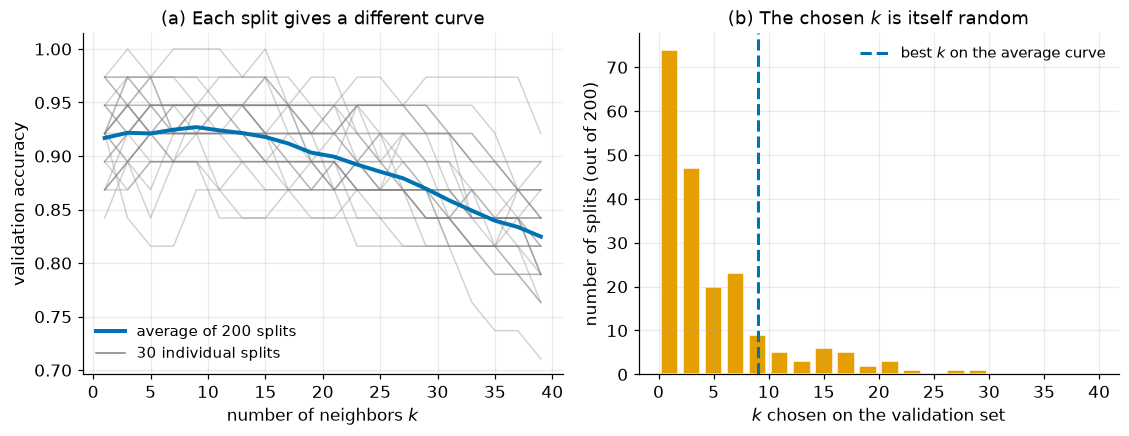

In [4]:
# Figure 5.1 — what the validation set can and cannot tell
def figure_5_1():
    fig, axes = plt.subplots(1, 2, figsize=(10.4, 4.1))
    ax = axes[0]
    for c in val_curves[:30]:
        ax.plot(ks_odd, c, color="gray", alpha=0.35, linewidth=1)
    ax.plot(ks_odd, val_curves.mean(axis=0), color=BLUE, linewidth=2.6, label="average of 200 splits")
    ax.plot([], [], color="gray", linewidth=1, label="30 individual splits")
    ax.set(xlabel="number of neighbors $k$", ylabel="validation accuracy", title="(a) Each split gives a different curve")
    ax.legend(frameon=False, fontsize=9.5, loc="lower left")
    ax = axes[1]
    counts = pd.Series(chosen_k).value_counts().reindex(ks_odd, fill_value=0)
    ax.bar(ks_odd, counts.to_numpy(), width=1.6, color=ORANGE, edgecolor="white")
    ax.axvline(ks_odd[np.argmax(val_curves.mean(axis=0))], color=BLUE, linestyle="--", linewidth=2,
               label="best $k$ on the average curve")
    ax.set(xlabel="$k$ chosen on the validation set", ylabel="number of splits (out of 200)",
           title="(b) The chosen $k$ is itself random")
    ax.legend(frameon=False, fontsize=9.5)
    fig.tight_layout()
    plt.show()


figure_5_1()

Panel (a) shows how much a validation curve depends on the split: individual curves wander by several points, and the spread across splits (a standard deviation of 0.037 at $k = 9$) is about what the binomial formula predicts (0.042). The average curve is nearly flat from $k = 1$ to $k \approx 15$, so the differences that we would like to detect are much smaller than the noise of a single split. Panel (b) shows the consequence: **the $k$ selected on one validation set is itself a random variable.** At least a quarter of the splits choose $k = 1$ (74 of 200), another quarter choose $k \ge 7$, and one split in twenty chooses $k \ge 17$, even though the best $k$ on the average curve is 9.

Two more numbers belong to the picture. The winner's validation accuracy, 0.944 on average, **overstates** its test accuracy, 0.924, by two points: this is the optimism of choosing the best of 20 noisy values. And on this plateau the choice matters little for the final accuracy: a fixed $k = 9$, which no single split could have identified, has a test accuracy of 0.929 against 0.924 for the $k$ chosen split by split. When the curve is flat, nothing is lost by choosing at random among the values on the plateau, but nothing is learned either: the **validation score of the winner is not a trustworthy measure of performance**, which the next experiment quantifies.

### Worked example 5.1 — can a validation set tell two models apart?

A validation set of $m = 100$ examples gives 90 correct predictions for model A and 93 for model B. (a) What are the standard errors? (b) Is the difference of three points significant? (c) How large must the validation set be to resolve a true difference of three points at two standard errors?

**(a)** $\hat p_A = 0.90$, $\operatorname{SE}_A = \sqrt{0.90\cdot 0.10/100} = 0.0300$; $\hat p_B = 0.93$, $\operatorname{SE}_B = \sqrt{0.93\cdot 0.07/100} = 0.0255$.

**(b)** Treating the two accuracies as independent, the standard error of the difference is $\sqrt{0.0300^2 + 0.0255^2} = 0.0394$, and the difference $0.03$ is only $0.03/0.0394 = 0.76$ standard errors: **not significant** (a $z$ of 2 would be needed). Section 5.5.1 shows that using the *same* examples for both models (a **paired** comparison) can be much more sensitive, but not enough to rescue a difference of three examples out of a hundred.

**(c)** We need $\operatorname{SE}_{\text{diff}} \le 0.03/2 = 0.015$, and with $p(1-p)$ averaging $0.078$ over the two models, $\operatorname{SE}_{\text{diff}} = \sqrt{2\cdot 0.078/m}$, so $m \ge 2\cdot 0.078/0.015^2 \approx 690$ examples. To resolve differences of one point one needs nine times more: more than 6,000. Let us check the arithmetic.

In [5]:
p_a, p_b, m_val = 0.90, 0.93, 100
se_a, se_b = np.sqrt(p_a * (1 - p_a) / m_val), np.sqrt(p_b * (1 - p_b) / m_val)
se_diff = np.sqrt(se_a ** 2 + se_b ** 2)
print(f"SE_A = {se_a:.4f}, SE_B = {se_b:.4f}, SE of the difference = {se_diff:.4f}, z = {(p_b - p_a) / se_diff:.2f}")
for diff in (0.03, 0.01):
    pq = (p_a * (1 - p_a) + p_b * (1 - p_b)) / 2
    print(f"validation size to resolve a difference of {diff} at 2 standard errors: {int(np.ceil(2 * pq / (diff / 2) ** 2))}")

SE_A = 0.0300, SE_B = 0.0255, SE of the difference = 0.0394, z = 0.76
validation size to resolve a difference of 0.03 at 2 standard errors: 690
validation size to resolve a difference of 0.01 at 2 standard errors: 6204


### 5.2.3 The winner's curse, measured

Section 3.4.1 showed, with coin-flip classifiers, that the best of $m$ useless candidates looks good. Here is the same phenomenon with *real data and a real, if silly, family of models*. On the Digits data (1,797 images of $8\times 8$ pixels) every candidate is a 1-nearest-neighbor classifier that looks at **8 randomly chosen pixels** only; the candidates differ in which pixels they see, and they are not equally good (some pixels are informative, some are almost always zero). This is a toy version of what happens when we select features, or hyperparameters, by trying many and keeping the best.

In each of 40 repetitions we draw 200 training images, 800 validation images and use the remaining 797 as test images. We generate 1,000 candidates, and for each size $m$ of the candidate pool (the first $m$ candidates) and for each size $n_{\text{val}}$ of the validation set (the first $n_{\text{val}}$ validation images) we pick the candidate with the best validation accuracy and record its **optimism**: validation accuracy of the winner minus its test accuracy.

In [6]:
digits = load_digits()
X_dg, y_dg = digits.data, digits.target


def selection_optimism(n_rep=40, n_train=200, n_val_pool=800, n_cand=1000, n_pixels=8,
                       n_vals=(50, 200, 800), pool_sizes=(1, 3, 10, 30, 100, 300, 1000), seed=SEED):
    """Optimism (validation accuracy minus test accuracy of the winner) of the best of m 1-NN candidates."""
    rng = np.random.default_rng(seed)
    n = len(y_dg)
    records = []
    for rep in range(n_rep):
        perm = rng.permutation(n)
        tr, va, te = perm[:n_train], perm[n_train:n_train + n_val_pool], perm[n_train + n_val_pool:]
        ev = np.concatenate([va, te])
        correct = np.zeros((n_cand, len(ev)), dtype=bool)
        for j in range(n_cand):
            pix = rng.choice(64, size=n_pixels, replace=False)
            A, B = X_dg[tr][:, pix], X_dg[ev][:, pix]
            d2 = (A ** 2).sum(1)[:, None] + (B ** 2).sum(1)[None, :] - 2 * A @ B.T   # squared distances, train x eval
            correct[j] = y_dg[tr][d2.argmin(axis=0)] == y_dg[ev]                   # 1-NN prediction is right?
        acc_test = correct[:, n_val_pool:].mean(axis=1)
        for n_val in n_vals:
            acc_val = correct[:, :n_val].mean(axis=1)
            for m in pool_sizes:
                b = int(np.argmax(acc_val[:m]))
                records.append((n_val, m, acc_val[b], acc_test[b]))
    out = pd.DataFrame(records, columns=["n_val", "m", "val", "test"])
    out["optimism"] = out["val"] - out["test"]
    return out


opt_runs = selection_optimism()
opt_table = (opt_runs.groupby(["n_val", "m"])
             .agg(val=("val", "mean"), test=("test", "mean"), optimism=("optimism", "mean"), sd=("optimism", "std"))
             .reset_index())
opt_table["bound"] = np.sqrt(np.log(opt_table["m"]) / (2 * opt_table["n_val"]))
print(opt_table[opt_table["m"].isin([1, 10, 100, 1000])].round(4).to_string(index=False))

 n_val    m    val   test  optimism     sd  bound
    50    1 0.4820 0.4931   -0.0111 0.0741 0.0000
    50   10 0.6445 0.5958    0.0487 0.0560 0.1517
    50  100 0.7395 0.6414    0.0981 0.0559 0.2146
    50 1000 0.8055 0.6692    0.1363 0.0616 0.2628
   200    1 0.4910 0.4931   -0.0021 0.0438 0.0000
   200   10 0.6190 0.6070    0.0120 0.0352 0.0759
   200  100 0.6940 0.6688    0.0252 0.0380 0.1073
   200 1000 0.7438 0.7041    0.0396 0.0350 0.1314
   800    1 0.4950 0.4931    0.0019 0.0269 0.0000
   800   10 0.6136 0.6108    0.0028 0.0238 0.0379
   800  100 0.6874 0.6785    0.0089 0.0233 0.0536
   800 1000 0.7280 0.7132    0.0147 0.0180 0.0657


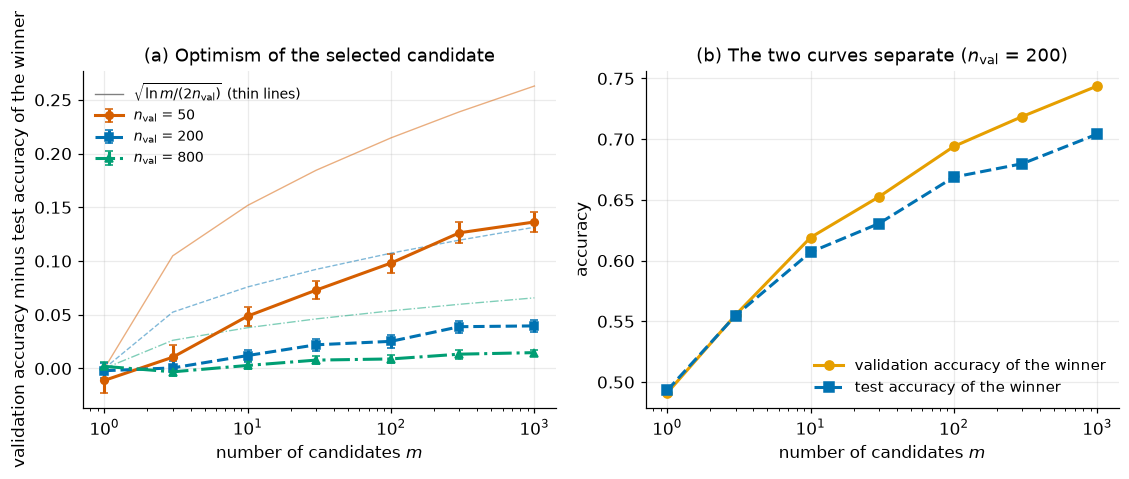

In [7]:
# Figure 5.2 — the optimism of the winner grows with the number of candidates and shrinks with the validation size
def figure_5_2():
    fig, axes = plt.subplots(1, 2, figsize=(10.4, 4.1))
    styles = {50: (VERMILION, "-", "o"), 200: (BLUE, "--", "s"), 800: (GREEN, "-.", "^")}
    ax = axes[0]
    for n_val, (color, ls, marker) in styles.items():
        sub = opt_table[opt_table["n_val"] == n_val]
        n_rep = opt_runs[(opt_runs["n_val"] == n_val) & (opt_runs["m"] == 1)].shape[0]
        ax.errorbar(sub["m"], sub["optimism"], yerr=sub["sd"] / np.sqrt(n_rep), color=color, linestyle=ls,
                    marker=marker, markersize=5, linewidth=2, capsize=2.5, label=f"$n_{{\\mathrm{{val}}}}$ = {n_val}")
        ax.plot(sub["m"], sub["bound"], color=color, linestyle=ls, linewidth=0.9, alpha=0.5)
    ax.plot([], [], color="gray", linewidth=0.9, label=r"$\sqrt{\ln m/(2n_{\mathrm{val}})}$ (thin lines)")
    ax.set_xscale("log")
    ax.set(xlabel="number of candidates $m$", ylabel="validation accuracy minus test accuracy of the winner",
           title="(a) Optimism of the selected candidate")
    ax.legend(frameon=False, fontsize=9)
    ax = axes[1]
    sub = opt_table[opt_table["n_val"] == 200]
    ax.plot(sub["m"], sub["val"], color=ORANGE, marker="o", linewidth=2, label="validation accuracy of the winner")
    ax.plot(sub["m"], sub["test"], color=BLUE, marker="s", linestyle="--", linewidth=2, label="test accuracy of the winner")
    ax.set_xscale("log")
    ax.set(xlabel="number of candidates $m$", ylabel="accuracy", title="(b) The two curves separate ($n_{\\mathrm{val}}$ = 200)")
    ax.legend(frameon=False, fontsize=9.5, loc="lower right")
    fig.tight_layout()
    plt.show()


figure_5_2()

Three facts stand out. First, at $m = 1$ the validation and test accuracies agree (about 0.49 for a 1-NN that sees 8 random pixels): a validation set is an honest judge of *one* model chosen in advance. Second, selection *works*: with $n_{\text{val}} = 200$ the test accuracy of the winner climbs from 0.49 to 0.70 as the pool grows from 1 to 1,000 candidates, because some pixel subsets really are better than others. But the winner's validation accuracy climbs faster, to 0.744, so the winner's score overstates its true performance by 4 points. Third, the optimism **shrinks as the validation set grows**: at $m = 1000$ it is 0.136 for $n_{\text{val}} = 50$, 0.040 for $n_{\text{val}} = 200$ and 0.015 for $n_{\text{val}} = 800$. With 50 validation images, selecting among a thousand candidates is a lottery: the winner scores 0.81 on the validation set and 0.67 on the test set.

The shape is the one predicted in Section 3.4 and by Theorem 3.1: the optimism grows only with the *logarithm* of the number of candidates (from 10 to 1,000 candidates, a hundred times as many, it goes from 0.012 to 0.040 for $n_{\text{val}} = 200$) and falls with the size of the validation set. The thin lines show the bound $\sqrt{\ln m/(2 n_{\text{val}})}$ of the theorem: it lies above the measured optimism everywhere, and is loose by a factor of two to three, as are the other bounds of Chapter 3.

The lesson is **not** "do not select": selection improved the test accuracy. The lesson is about *reporting*. The score of the winner on the data that selected it is an overestimate, and the overestimate grows with the number of things that we tried and shrinks with the amount of validation data.

:::{admonition} Pitfall — reporting the best validation score
:class: warning
"We tried 200 settings and the best reached 96% on the validation set" is **not** an estimate of how the model will perform. The honest sequence is: choose on the validation data (or by cross-validation), then evaluate the chosen model **once** on the test data and report *that* number, with a confidence interval (Section 3.10.2). If you have tried a very large number of candidates, expect the optimism to be large and the validation set to be too small to tell them apart.
:::

## 5.3 Cross-validation

A single validation set wastes data twice: the examples in it are not used for training, and (as Figure 5.1 showed) the estimate that it provides is noisy. **Cross-validation** (CV) reuses every example both for training and for validation, in turns.

### 5.3.1 The K-fold idea

Split the $n$ examples at random into $K$ parts of nearly equal size, the **folds**. For each fold $\kappa = 1, \dots, K$: train the model on the other $K-1$ folds, and compute its predictions on the fold $\kappa$ that was held out. Every example is then predicted **once**, by a model that did not see it. Writing $\kappa(i)$ for the fold that contains example $i$ and $\hat f^{-\kappa}$ for the model trained without fold $\kappa$, the cross-validation estimate of the risk is
$$
\mathrm{CV}_K \;=\; \frac1n \sum_{i=1}^{n} \ell\big(y_i,\ \hat f^{-\kappa(i)}(\mathbf{x}_i)\big).
$$
Figure 5.3 shows the scheme for $K = 5$. The cost is $K$ model fits instead of one. The extreme case $K = n$ (one example per fold) is **leave-one-out** cross-validation (LOO). Typical values are $K = 5$ or $K = 10$.

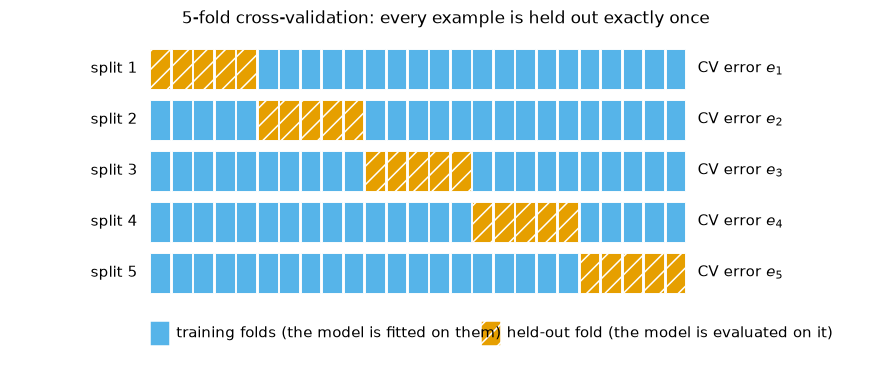

In [8]:
# Figure 5.3 — the scheme of 5-fold cross-validation
from matplotlib.patches import Rectangle


def figure_5_3():
    K, n_blocks = 5, 25
    fig, ax = plt.subplots(figsize=(8.4, 3.5))
    for kappa in range(K):
        for b in range(n_blocks):
            fold = b // (n_blocks // K)
            held_out = fold == kappa
            ax.add_patch(Rectangle((b, K - 1 - kappa), 0.92, 0.78, facecolor=ORANGE if held_out else SKY,
                                   edgecolor="white", hatch="//" if held_out else None, linewidth=0.6))
        ax.text(-0.6, K - 1 - kappa + 0.39, f"split {kappa + 1}", ha="right", va="center", fontsize=10)
        ax.text(n_blocks + 0.5, K - 1 - kappa + 0.39, f"CV error $e_{kappa + 1}$", ha="left", va="center", fontsize=10)
    ax.add_patch(Rectangle((0, -1.05), 0.92, 0.5, facecolor=SKY, edgecolor="white"))
    ax.text(1.2, -0.8, "training folds (the model is fitted on them)", va="center", fontsize=9.5)
    ax.add_patch(Rectangle((15.4, -1.05), 0.92, 0.5, facecolor=ORANGE, edgecolor="white", hatch="//"))
    ax.text(16.6, -0.8, "held-out fold (the model is evaluated on it)", va="center", fontsize=9.5)
    ax.set_xlim(-6.5, n_blocks + 9)
    ax.set_ylim(-1.3, K + 0.1)
    ax.axis("off")
    ax.set_title("5-fold cross-validation: every example is held out exactly once", fontsize=11)
    fig.tight_layout()
    plt.show()


figure_5_3()

Cross-validation in code takes a dozen lines. We write it from scratch, for any scikit-learn estimator, and compare it with `cross_val_score` on the same folds. The model is 3-NN on the Digits data.

In [9]:
from sklearn.base import clone
from sklearn.model_selection import cross_val_score


def kfold_splits(n, K, seed):
    """K random folds: a list of (train indices, held-out indices)."""
    folds = np.array_split(np.random.default_rng(seed).permutation(n), K)
    return [(np.concatenate([folds[j] for j in range(K) if j != kappa]), folds[kappa]) for kappa in range(K)]


def cv_accuracies(model, X, y, splits):
    """Accuracy on each held-out fold, for a model trained on the other folds."""
    scores = []
    for train, held_out in splits:
        fitted = clone(model).fit(X[train], y[train])           # a fresh, unfitted copy for every fold
        scores.append(np.mean(fitted.predict(X[held_out]) == y[held_out]))
    return np.array(scores)


splits = kfold_splits(len(y_dg), K=5, seed=SEED)
mine = cv_accuracies(KNeighborsClassifier(n_neighbors=3), X_dg, y_dg, splits)
theirs = cross_val_score(KNeighborsClassifier(n_neighbors=3), X_dg, y_dg, cv=splits)   # the same folds, given as a list
print("from scratch :", mine.round(4), f" mean {mine.mean():.4f}")
print("scikit-learn :", theirs.round(4), f" mean {theirs.mean():.4f}")
print("identical:", np.allclose(mine, theirs))

from scratch : [0.9917 0.9833 0.9861 0.9861 0.9833]  mean 0.9861
scikit-learn : [0.9917 0.9833 0.9861 0.9861 0.9833]  mean 0.9861
identical: True


The fold-wise accuracies (in the output above they run from 0.983 to 0.992 on Digits) are often reported as "mean $\pm$ standard deviation". Before using that number we must understand what it estimates, and how good an estimate it is.

### 5.3.2 What does cross-validation estimate?

Two questions: is $\mathrm{CV}_K$ *biased*, and how *variable* is it? The answer to the first is easy to guess. Each of the $K$ models is trained on $n(K-1)/K$ examples, fewer than the $n$ of the final model. Since a model trained on less data is, on average, worse (the learning curves of Chapter 3), $\mathrm{CV}_K$ is **pessimistic**: it estimates the risk of a model trained on $n(K-1)/K$ examples, and the smaller $K$ is the worse the bias is. Leave-one-out has almost no such bias ($n - 1$ examples).

To measure all of this we need a situation where the *true* error of the final model can be computed. We use the real Digits data as a population of 1,797 images. In each of 400 repetitions we draw a random **sample of $n = 100$ images**, compute the CV estimates of 3-NN accuracy on it (with $K = 2, 5, 10, 20$ and LOO), fit the model on all 100 images, and measure its accuracy on the other 1,697 images, which gives an almost exact value of the performance that the CV estimates are meant to predict. To keep 400 repetitions cheap we compute the distance matrix of each sample once (Gram matrix of Worked example 2.1) and reuse it in every fold; the first lines check that this hand-made 3-NN agrees with scikit-learn.

In [10]:
def sq_dist(A, B):
    """Squared Euclidean distances between the rows of A and the rows of B (Gram-matrix trick of Chapter 2)."""
    return (A ** 2).sum(1)[:, None] + (B ** 2).sum(1)[None, :] - 2 * A @ B.T


def knn_vote(D, y_train, k):
    """Majority label among the k nearest training points; D has one row per query and one column per training point."""
    nearest = np.argpartition(D, k - 1, axis=1)[:, :k]
    return np.array([np.bincount(row, minlength=10).argmax() for row in y_train[nearest]])


def cv_from_distances(D, y, splits, k):
    """K-fold accuracies of k-NN when the matrix D of all pairwise distances has been computed once."""
    return np.array([np.mean(knn_vote(D[np.ix_(held, train)], y[train], k) == y[held]) for train, held in splits])


# Check against scikit-learn on a sample of 100 images (small differences are possible only when distances tie)
rng = np.random.default_rng(SEED)
s = rng.permutation(len(y_dg))[:100]
chk_splits = kfold_splits(100, 5, SEED)
mine = cv_from_distances(sq_dist(X_dg[s], X_dg[s]), y_dg[s], chk_splits, 3)
ref = cross_val_score(KNeighborsClassifier(n_neighbors=3), X_dg[s], y_dg[s], cv=chk_splits)
print("hand-made vs scikit-learn on a sample of 100:", mine.round(3), ref.round(3))

hand-made vs scikit-learn on a sample of 100: [0.9  0.75 0.9  0.9  0.95] [0.9  0.75 0.9  0.9  0.95]


In [11]:
Ks = [2, 5, 10, 20, 100]          # K = 100 = n is leave-one-out
n_s, k_nn, n_rep = 100, 3, 400
rng = np.random.default_rng(SEED)
records, shuffle_sd = [], []
for rep in range(n_rep):
    perm = rng.permutation(len(y_dg))
    s, t = perm[:n_s], perm[n_s:]                                   # the sample, and the rest (almost-exact truth)
    D = sq_dist(X_dg[s], X_dg[s])
    row = {"test": np.mean(knn_vote(sq_dist(X_dg[t], X_dg[s]), y_dg[s], k_nn) == y_dg[t])}
    for K in Ks:
        fold_acc = cv_from_distances(D, y_dg[s], kfold_splits(n_s, K, seed=int(rng.integers(10 ** 6))), k_nn)
        row[f"cv{K}"] = fold_acc.mean()
        if K == 10:
            row["naive_se"] = fold_acc.std(ddof=1) / np.sqrt(K)      # the usual "standard error of the mean of the folds"
    if rep < 100:                                                   # noise due only to the random assignment of the folds
        shuffle_sd.append(np.std([cv_from_distances(D, y_dg[s], kfold_splits(n_s, 10, seed=r), k_nn).mean() for r in range(20)], ddof=1))
    records.append(row)
cv_runs = pd.DataFrame(records)

rows = []
for K in Ks:
    err = cv_runs[f"cv{K}"] - cv_runs["test"]
    rows.append({"K": "LOO" if K == n_s else K, "training size": n_s - n_s // K if K < n_s else n_s - 1,
                 "mean CV accuracy": cv_runs[f"cv{K}"].mean(), "bias (CV - test)": err.mean(),
                 "sd of (CV - test)": err.std(), "corr(CV, test)": np.corrcoef(cv_runs[f"cv{K}"], cv_runs["test"])[0, 1]})
print(f"mean test accuracy of the models fitted on the 100 images: {cv_runs['test'].mean():.4f}  (sd across samples {cv_runs['test'].std():.4f})")
print(pd.DataFrame(rows).round(4).to_string(index=False))
err10 = cv_runs["cv10"] - cv_runs["test"]
print(f"\nK = 10: the 'standard error' computed from the 10 fold scores is {cv_runs['naive_se'].mean():.4f} on average,"
      f" but the standard deviation of the actual error CV - test is {err10.std():.4f}")
print(f"K = 10: sd of the CV estimate caused by the random choice of the folds alone: {np.mean(shuffle_sd):.4f}"
      f"  (total sd of the CV estimate across samples: {cv_runs['cv10'].std():.4f})")

mean test accuracy of the models fitted on the 100 images: 0.8763  (sd across samples 0.0204)
  K  training size  mean CV accuracy  bias (CV - test)  sd of (CV - test)  corr(CV, test)
  2             50            0.7628           -0.1135             0.0634         -0.1976
  5             80            0.8469           -0.0294             0.0444         -0.0272
 10             90            0.8621           -0.0142             0.0415         -0.0205
 20             95            0.8685           -0.0078             0.0418         -0.0233
LOO             99            0.8732           -0.0031             0.0411         -0.0214

K = 10: the 'standard error' computed from the 10 fold scores is 0.0339 on average, but the standard deviation of the actual error CV - test is 0.0415
K = 10: sd of the CV estimate caused by the random choice of the folds alone: 0.0154  (total sd of the CV estimate across samples: 0.0357)


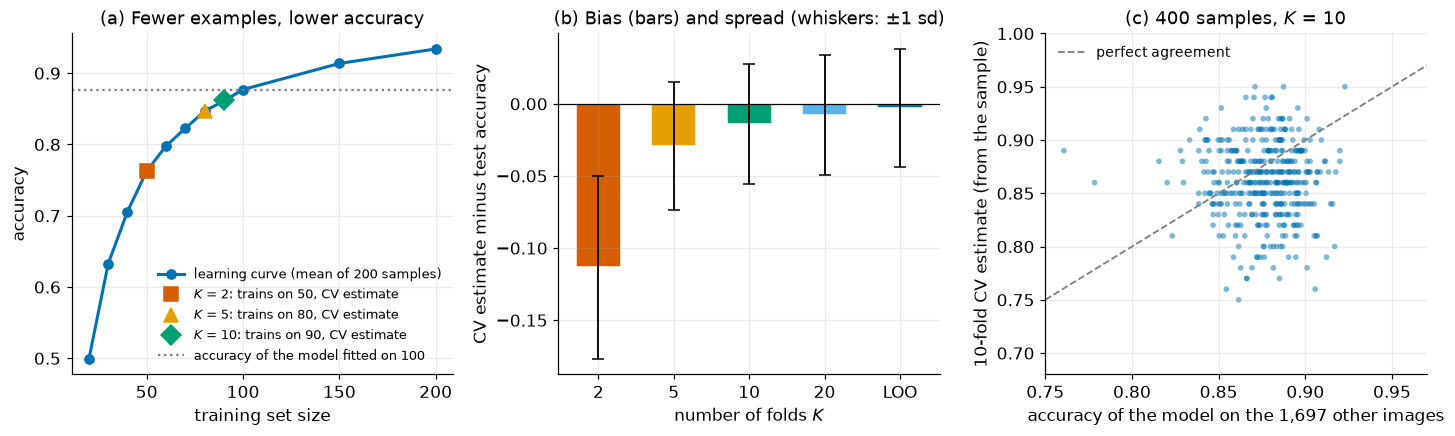

In [12]:
# learning curve of 3-NN on Digits: mean accuracy as a function of the training size
rng = np.random.default_rng(SEED)
lc_sizes = [20, 30, 40, 50, 60, 70, 80, 90, 100, 150, 200]
lc_acc = []
for m in lc_sizes:
    acc = []
    for _ in range(200):
        perm = rng.permutation(len(y_dg))
        tr, te = perm[:m], perm[m:]
        acc.append(np.mean(knn_vote(sq_dist(X_dg[te], X_dg[tr]), y_dg[tr], k_nn) == y_dg[te]))
    lc_acc.append(np.mean(acc))
lc_acc = np.array(lc_acc)


# Figure 5.4 — bias and noise of cross-validation
def figure_5_4():
    fig, axes = plt.subplots(1, 3, figsize=(13.2, 4.1))
    ax = axes[0]
    ax.plot(lc_sizes, lc_acc, color=BLUE, marker="o", linewidth=2, label="learning curve (mean of 200 samples)")
    for K, marker, color in [(2, "s", VERMILION), (5, "^", ORANGE), (10, "D", GREEN)]:
        size = n_s - n_s // K
        ax.plot([size], [cv_runs[f"cv{K}"].mean()], marker=marker, color=color, markersize=9, linestyle="none",
                label=f"$K$ = {K}: trains on {size}, CV estimate")
    ax.axhline(cv_runs["test"].mean(), color="gray", linestyle=":", linewidth=1.5, label="accuracy of the model fitted on 100")
    ax.set(xlabel="training set size", ylabel="accuracy", title="(a) Fewer examples, lower accuracy")
    ax.legend(frameon=False, fontsize=8.3, loc="lower right")
    ax = axes[1]
    labels = ["2", "5", "10", "20", "LOO"]
    errs = [cv_runs[f"cv{K}"] - cv_runs["test"] for K in Ks]
    ax.bar(labels, [e.mean() for e in errs], color=[VERMILION, ORANGE, GREEN, SKY, BLUE], edgecolor="white", width=0.6)
    ax.errorbar(labels, [e.mean() for e in errs], yerr=[e.std() for e in errs], fmt="none", ecolor="black", capsize=4, linewidth=1.2)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set(xlabel="number of folds $K$", ylabel="CV estimate minus test accuracy",
           title="(b) Bias (bars) and spread (whiskers: ±1 sd)")
    ax = axes[2]
    ax.scatter(cv_runs["test"], cv_runs["cv10"], s=14, color=BLUE, alpha=0.5, edgecolor="none")
    lo, hi = 0.75, 0.97
    ax.plot([lo, hi], [lo, hi], color="gray", linestyle="--", linewidth=1.2, label="perfect agreement")
    ax.set(xlabel="accuracy of the model on the 1,697 other images", ylabel="10-fold CV estimate (from the sample)",
           title="(c) 400 samples, $K$ = 10", xlim=(lo, hi), ylim=(0.68, 1.0))
    ax.legend(frameon=False, fontsize=9, loc="upper left")
    fig.tight_layout()
    plt.show()


figure_5_4()

Five facts stand out in the table and in Figure 5.4.

1. **Bias.** The CV estimate is too low, by 11 points for $K = 2$, 3 points for $K = 5$, 1.4 points for $K = 10$, 0.8 points for $K = 20$ and 0.3 points for LOO. The bias can be read off the **learning curve** (panel (a)): each CV estimate sits on the curve at the training size $n(K-1)/K$. With only 100 images for 10 classes the curve is steep, so halving the training set costs a lot; on a problem whose learning curve is flat the bias would be negligible.
2. **Noise.** Even for $K = 10$ the error of the CV estimate has a standard deviation of 0.042: *four points*, as large as the differences between many reasonable models. Larger $K$ reduces the bias at the price of $K$ fits; beyond $K = 10$ the gain is smaller than the noise.
3. **The usual "standard error" is too small.** The standard error computed from the ten fold scores, $s/\sqrt{K}$, is 0.034 on average, against an actual error of 0.042. The ten scores are not independent, because the training sets of different folds overlap, and Bengio and Grandvalet (2004) proved that **no unbiased estimator of the variance of $K$-fold cross-validation exists**. Quoting "mean $\pm$ sd$/\sqrt{K}$" is therefore a lower bound on the uncertainty, not an estimate of it.
4. **Repeating the folds helps only a little.** The random assignment of the examples to folds contributes a standard deviation of 0.015 to the estimate, against a total of 0.036; averaging over repetitions removes the former and leaves the latter, which comes from the finite sample.
5. **CV estimates the quality of a procedure, not of this model.** Panel (c) plots, for 400 samples, the CV estimate against the accuracy of the model actually fitted on the sample. The cloud is round: the correlation is $-0.02$. CV is right *on average* (the bias at $K = 10$ is 1.4 points) but tells almost nothing about whether *this* sample gave a lucky or an unlucky model. This is a general property of cross-validation (Bates, Hastie and Tibshirani, 2024), and it is why a final model is judged on a test set that it has never touched.

:::{admonition} Key idea — what cross-validation is for
:class: tip
Cross-validation estimates how well a **learning procedure** (an algorithm together with the rule that sets its hyperparameters) performs on training sets of size $n(K-1)/K$, with a pessimistic bias that depends on $K$ and on how steep the learning curve is, and with an error of several points when $n$ is small. Use it to **compare and tune procedures**; take $K = 5$ or $K = 10$ as the default; do not read its output as a certificate for the particular model that you finally fit.
:::

### 5.3.3 Splits that respect the structure of the data

Random folds are right only when the examples are exchangeable and the folds are representative. Four common situations break one of these conditions.

**Order in the file.** Many data sets are sorted (by class, by date, by site). The Wine data, for instance, list all the examples of cultivar 0, then cultivar 1, then cultivar 2. Taking the first fifth of the rows as fold 1 (`KFold` without shuffling) gives a first fold made of one cultivar only, and training and test folds that follow different distributions. Shuffling fixes this; **stratification** goes further and keeps the class proportions of the whole data set in every fold, which matters especially when a class is small. Below, 5-NN on all 13 (standardized) features of Wine, with the three kinds of folds; the shuffled and stratified versions are repeated 20 times, because one shuffle is itself noisy.

In [13]:
from sklearn.model_selection import KFold, StratifiedKFold, RepeatedKFold, RepeatedStratifiedKFold

X_w, y_w_all = wine.data.to_numpy(), wine.target.to_numpy()
pipe_w = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
print("rows sorted by cultivar:", bool((np.diff(y_w_all) >= 0).all()), "- examples per cultivar:", np.bincount(y_w_all).tolist())
print("class counts in the 5 folds of KFold(5) without shuffling (rows: folds; columns: cultivars):")
for _, held in KFold(5).split(X_w):
    print("   ", np.bincount(y_w_all[held], minlength=3).tolist())

acc_plain = cross_val_score(pipe_w, X_w, y_w_all, cv=KFold(5)).mean()
acc_shuf = cross_val_score(pipe_w, X_w, y_w_all, cv=RepeatedKFold(n_splits=5, n_repeats=20, random_state=SEED))
acc_strat = cross_val_score(pipe_w, X_w, y_w_all, cv=RepeatedStratifiedKFold(n_splits=5, n_repeats=20, random_state=SEED))
print(f"\nKFold(5), file order           : {acc_plain:.4f}")
print(f"KFold(5), shuffled (20 repeats) : mean {acc_shuf.mean():.4f}, sd of the 5-fold means {acc_shuf.reshape(20, 5).mean(axis=1).std():.4f}")
print(f"stratified (20 repeats)         : mean {acc_strat.mean():.4f}, sd of the 5-fold means {acc_strat.reshape(20, 5).mean(axis=1).std():.4f}")

rows sorted by cultivar: True - examples per cultivar: [59, 71, 48]
class counts in the 5 folds of KFold(5) without shuffling (rows: folds; columns: cultivars):
    [36, 0, 0]
    [23, 13, 0]
    [0, 36, 0]
    [0, 22, 13]
    [0, 0, 35]



KFold(5), file order           : 0.8935
KFold(5), shuffled (20 repeats) : mean 0.9593, sd of the 5-fold means 0.0096
stratified (20 repeats)         : mean 0.9622, sd of the 5-fold means 0.0071


The file-order folds are almost pure: the first fold is entirely cultivar 0, the third entirely cultivar 1, the last entirely cultivar 2. The model is trained on a mixture of classes different from the one it is tested on, and the estimated accuracy, 0.894, is **six to seven points below** the shuffled one (0.959) and the stratified one (0.962). Stratification adds little to the *mean* on this balanced problem, but it reduces the variability that comes from the random assignment (a standard deviation of the 5-fold means of 0.007 instead of 0.010), and its value grows when a class is rare: with 5% of positives and random folds, some fold may contain almost none.

**Repeated folds.** The random assignment of the examples to the folds is a source of noise of its own (the output of Section 5.3.2 measured it for $K=10$). **Repeated $K$-fold** runs the whole procedure several times with different assignments and averages: it is cheap insurance, particularly for small data sets, and it is what `RepeatedStratifiedKFold` does. It reduces *only* the noise of the folds; the noise due to the finite sample, which is the larger one, remains.

**Groups.** Often the rows are not independent: several images of the same patient, several measurements of the same machine, several sentences of the same author. A random split then puts rows of the same group in the training and in the held-out folds, and the model is rewarded for **recognizing the group**, not for generalizing to new ones. If the model will be applied to *new* patients, the folds must be formed from whole patients (`GroupKFold`, `GroupShuffleSplit`). The scikit-learn data sets have no group labels, so here is a **simulation**, flagged as such: 40 "patients" with 10 measurements each; each patient has a characteristic profile of 5 features (the measurements are the profile plus a little noise) and a label that is a fair coin flip *unrelated to the profile*. No model can predict the label of a new patient better than by chance.

In [14]:
from sklearn.model_selection import GroupKFold, TimeSeriesSplit

n_patients, per_patient = 40, 10
groups = np.repeat(np.arange(n_patients), per_patient)
rec_acc, grp_acc = [], []
for sim in range(30):
    rng = np.random.default_rng(sim)
    profile = rng.normal(size=(n_patients, 5))                     # characteristic profile of each patient
    label = rng.integers(0, 2, size=n_patients)                     # a coin flip per patient, unrelated to the profile
    X_g = np.repeat(profile, per_patient, axis=0) + 0.3 * rng.normal(size=(n_patients * per_patient, 5))
    y_g = np.repeat(label, per_patient)
    knn5 = KNeighborsClassifier(n_neighbors=5)
    rec_acc.append(cross_val_score(knn5, X_g, y_g, cv=KFold(5, shuffle=True, random_state=sim)).mean())
    grp_acc.append(cross_val_score(knn5, X_g, y_g, cv=GroupKFold(5), groups=groups).mean())
print("simulated patients, 30 data sets: accuracy of 5-NN, mean over data sets")
print(f"  random folds (rows of one patient on both sides): {np.mean(rec_acc):.3f}")
print(f"  folds made of whole patients (GroupKFold)       : {np.mean(grp_acc):.3f}   (the true accuracy is 0.5)")

simulated patients, 30 data sets: accuracy of 5-NN, mean over data sets
  random folds (rows of one patient on both sides): 0.946
  folds made of whole patients (GroupKFold)       : 0.522   (the true accuracy is 0.5)


Random folds report 95% accuracy for a problem with no signal at all; grouped folds report the truth. The same logic applies to **leaking duplicates**, to images from the same video, and to any data where "new" in production means "from a new source".

**Time.** When the data are ordered in time and the model will predict the *future*, the folds must respect the order: train on the past, validate on what comes after. `TimeSeriesSplit` does exactly this, with a training window that grows. Training on the future to predict the past is a leak, even if no row is used twice.

In [15]:
for train, held in TimeSeriesSplit(n_splits=4).split(np.arange(10)):
    print("train on", train.tolist(), "-> validate on", held.tolist())

train on [0, 1] -> validate on [2, 3]
train on [0, 1, 2, 3] -> validate on [4, 5]
train on [0, 1, 2, 3, 4, 5] -> validate on [6, 7]
train on [0, 1, 2, 3, 4, 5, 6, 7] -> validate on [8, 9]


:::{admonition} Pitfall — anything that learns from data belongs inside the loop
:class: warning
Standardization, imputation, outlier clipping, feature selection, dimensionality reduction, resampling: each of these *learns something from the data* (a mean, a set of columns, a direction). Done on the whole data set **before** the split, it lets information from the held-out fold into the training step. Section 2.7 showed that choosing features on the whole data set gave 82% accuracy on pure noise; Exercise 4.9 repeated it with $k$-NN. The rule is mechanical: put every such step in a `Pipeline` and give the *pipeline* to the cross-validation routine, as we have done in all the experiments of this chapter, so that it is refitted on each training part. The same rule applies to the choice of hyperparameters, which is the subject of the next section.
:::

## 5.4 Choosing hyperparameters

A model has two kinds of numbers. **Parameters** are fitted by the learning algorithm (the weights of a linear model, the stored examples of $k$-NN). **Hyperparameters** are set *before* fitting and control the model's flexibility or the algorithm's behavior: the number of neighbors $k$, the distance and the weighting scheme of Chapter 4, and the regularization strengths and tree depths of the coming chapters. A hyperparameter cannot be chosen by minimizing the training error (the training error always asks for the most flexible model, Figure 4.3), so it is chosen by **estimating the performance of each candidate setting on data that were not used to fit it**, which is exactly what Sections 5.2 and 5.3 provide.

### 5.4.1 Grid search with cross-validation

The simplest procedure: list a finite set of values for each hyperparameter, evaluate every combination by cross-validation, and keep the best. In scikit-learn this is `GridSearchCV`. Hyperparameters of a step inside a pipeline are addressed with the name of the step, two underscores, and the name of the hyperparameter (`knn__n_neighbors`). After the search, `GridSearchCV` **refits** the best configuration on the whole training set it was given, so that `search.predict` is ready to use.

Our data are the 569 patients of the Breast Cancer data set. We keep 25% of them (143 patients) aside as a **test set**, and do everything else on the other 426. The model is a standardized $k$-NN; the grid has 15 odd values of $k$, two weighting schemes and two Minkowski distances ($p = 1$, Manhattan, and $p = 2$, Euclidean), 60 configurations in all. Each is evaluated by 5-fold stratified cross-validation repeated 3 times.

In [16]:
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, RepeatedStratifiedKFold
from sklearn.pipeline import Pipeline

X_bc, y_bc = load_breast_cancer(return_X_y=True)
X_trbc, X_tebc, y_trbc, y_tebc = train_test_split(X_bc, y_bc, test_size=0.25, random_state=SEED, stratify=y_bc)
print(f"training set: {len(y_trbc)} patients, test set (not touched until the end): {len(y_tebc)} patients")

pipe_bc = Pipeline([("scale", StandardScaler()), ("knn", KNeighborsClassifier())])
param_grid = {"knn__n_neighbors": list(range(1, 31, 2)),
              "knn__weights": ["uniform", "distance"],
              "knn__p": [1, 2]}
cv_rep = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
search = GridSearchCV(pipe_bc, param_grid, cv=cv_rep).fit(X_trbc, y_trbc)

results = pd.DataFrame(search.cv_results_)
results["se"] = results["std_test_score"] / np.sqrt(5)       # spread of the fold scores, divided by sqrt(5) (the repeats are not independent)
top = results.sort_values("rank_test_score")[["param_knn__n_neighbors", "param_knn__weights", "param_knn__p",
                                              "mean_test_score", "std_test_score", "rank_test_score"]]
top.columns = ["k", "weights", "p", "mean CV accuracy", "sd of fold scores", "rank"]
print(f"{len(results)} configurations, {len(results) * 15} model fits for the search")
print(top.head(8).round(4).to_string(index=False))
best = results.loc[results["rank_test_score"] == 1].iloc[0]
n_close = int((results["mean_test_score"] >= best["mean_test_score"] - best["se"]).sum())
print(f"\nbest: {search.best_params_}, CV accuracy {search.best_score_:.4f}")
print(f"configurations within one standard error ({best['se']:.4f}) of the best: {n_close} of {len(results)}")
print(f"spread between the best and the 30th configuration: {best['mean_test_score'] - results['mean_test_score'].sort_values(ascending=False).iloc[29]:.4f}")

training set: 426 patients, test set (not touched until the end): 143 patients


60 configurations, 900 model fits for the search
 k  weights  p  mean CV accuracy  sd of fold scores  rank
15 distance  2            0.9695             0.0112     1
11  uniform  2            0.9695             0.0094     2
11 distance  2            0.9695             0.0094     2
13 distance  2            0.9695             0.0128     4
13  uniform  2            0.9687             0.0119     5
 9 distance  2            0.9687             0.0147     6
 9  uniform  2            0.9687             0.0147     6
 5  uniform  2            0.9679             0.0152     8

best: {'knn__n_neighbors': 15, 'knn__p': 2, 'knn__weights': 'distance'}, CV accuracy 0.9695
configurations within one standard error (0.0050) of the best: 24 of 60
spread between the best and the 30th configuration: 0.0071


The search took 900 model fits (60 configurations times 15 folds) and returned $k = 15$ with distance weights and the Euclidean distance, with a CV accuracy of 0.9695. But read the table, not just the winner. The top eight configurations are all within 0.2 points of each other and all use the Euclidean distance; **24 of the 60 configurations are within one standard error (0.0050) of the best**, and the first 30 span only 0.7 points. The data do not support the choice of the winner over its many near-ties: another sample of 426 patients would very likely have crowned a different one. Only the clearly bad corner of the grid (very small or very large $k$) is excluded with confidence. This is the usual picture of a tuning problem: a noisy plateau at the top, and a clear region of poor settings.

### The one-standard-error rule

When many configurations are tied within the noise, the choice among them should rest on something other than a coin flip. The **one-standard-error rule** (Breiman et al., 1984; Hastie, Tibshirani and Friedman, 2009) says: find the best configuration, compute the standard error of its CV score, and among the configurations whose score is within one standard error of the best, **choose the simplest** (the least flexible). The reasoning is the bias–variance trade-off of Chapter 4: complexity costs variance, and a simpler model that is statistically indistinguishable from the best is the safer bet. For $k$-NN the simplest model is the one with the largest $k$. Figure 5.5 applies the rule to the cross-validation curve of $k$ (uniform weights, Euclidean distance).

best k: 11 (CV accuracy 0.9695, SE 0.0042);  one-SE rule picks k = 13 (CV accuracy 0.9687)


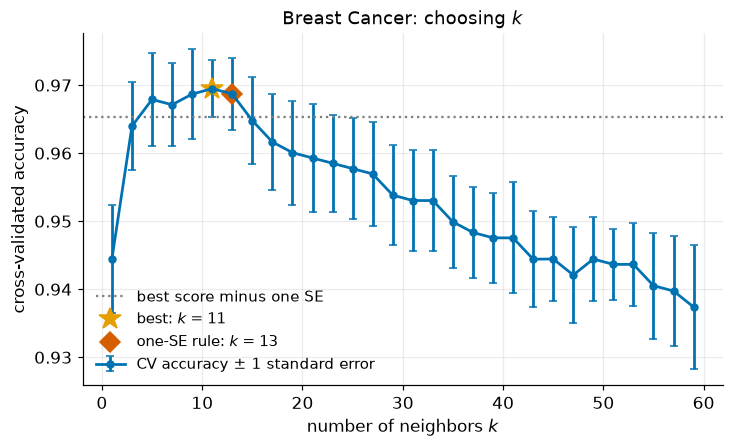

In [17]:
ks_curve = np.arange(1, 61, 2)
curve_search = GridSearchCV(pipe_bc, {"knn__n_neighbors": ks_curve.tolist()}, cv=cv_rep).fit(X_trbc, y_trbc)
cm = np.array(curve_search.cv_results_["mean_test_score"])
cse = np.array(curve_search.cv_results_["std_test_score"]) / np.sqrt(5)
i_best = int(np.argmax(cm))
threshold = cm[i_best] - cse[i_best]
k_best = int(ks_curve[i_best])
k_1se = int(ks_curve[np.max(np.where(cm >= threshold)[0])])       # the largest k within one SE of the best
print(f"best k: {k_best} (CV accuracy {cm[i_best]:.4f}, SE {cse[i_best]:.4f});  one-SE rule picks k = {k_1se} (CV accuracy {cm[ks_curve == k_1se][0]:.4f})")


# Figure 5.5 — the CV curve of k and the one-standard-error rule
def figure_5_5():
    fig, ax = plt.subplots(figsize=(6.8, 4.2))
    ax.errorbar(ks_curve, cm, yerr=cse, color=BLUE, marker="o", markersize=4.5, linewidth=1.8, capsize=2.5,
                label="CV accuracy ± 1 standard error")
    ax.axhline(threshold, color="gray", linestyle=":", linewidth=1.5, label="best score minus one SE")
    ax.plot([k_best], [cm[i_best]], marker="*", markersize=15, color=ORANGE, linestyle="none", label=f"best: $k$ = {k_best}")
    ax.plot([k_1se], [cm[ks_curve == k_1se][0]], marker="D", markersize=9, color=VERMILION, linestyle="none",
            label=f"one-SE rule: $k$ = {k_1se}")
    ax.set(xlabel="number of neighbors $k$", ylabel="cross-validated accuracy", title="Breast Cancer: choosing $k$")
    ax.legend(frameon=False, fontsize=9.5, loc="lower left")
    fig.tight_layout()
    plt.show()


figure_5_5()

The CV accuracy rises from about 0.94 at $k = 1$ to a plateau of about 0.97 for $k$ between 5 and 13, then declines slowly. The best value is $k = 11$ and the one-standard-error rule moves to $k = 13$. Here the standard error is small (0.004) because the problem is easy, so the rule changes little; it matters more when the curve is flat and noisy, where it prevents us from choosing a very flexible model on the strength of a difference that is only noise. The standard error used here is itself approximate, for the reasons of Section 5.3.2.

### 5.4.2 Random search, and the scale of the search

A grid has a weakness: its cost multiplies with every hyperparameter, and most of the evaluations are spent on repeating the same few values of the hyperparameter that matters. If the score depends strongly on one hyperparameter and weakly on another, a $3\times 3$ grid tries only **three** distinct values of the important one, while nine random points try **nine** (Bergstra and Bengio, 2012). **Random search** draws each hyperparameter independently from a distribution (a list of values, an integer range, a *log-uniform* range for scale-like quantities) and evaluates a fixed number of random configurations. It is the better default whenever there are more than two or three hyperparameters, and the budget is simply the number of draws.

To see the effect without confounders we use a **schematic** (a simulation, not a real data set): a score that is a bump in the important hyperparameter $x$, with its peak at an unknown position, plus a small dependence on the unimportant $y$. We compare the best of nine grid points with the best of nine random points, over 2,000 random positions of the peak.

In [18]:
def toy_score(x, y, peak):
    """Illustrative score: a bump in x (important), a gentle slope in y (unimportant)."""
    return np.exp(-((x - peak) / 0.12) ** 2) + 0.05 * y


rng = np.random.default_rng(SEED)
g1 = np.array([1 / 6, 3 / 6, 5 / 6])
grid_pts = np.array([(a, b) for a in g1 for b in g1])           # 3 x 3 grid in the unit square
best_grid, best_rand = [], []
for _ in range(2000):
    peak = rng.uniform(0.1, 0.9)
    best_grid.append(toy_score(grid_pts[:, 0], grid_pts[:, 1], peak).max())
    rand_pts = rng.uniform(size=(9, 2))
    best_rand.append(toy_score(rand_pts[:, 0], rand_pts[:, 1], peak).max())
print(f"best score reached with 9 evaluations (the maximum possible is about 1.05): grid {np.mean(best_grid):.3f}, random {np.mean(best_rand):.3f}")
print(f"distinct values of the important hyperparameter tried: grid {len(g1)}, random 9")

best score reached with 9 evaluations (the maximum possible is about 1.05): grid 0.692, random 0.816
distinct values of the important hyperparameter tried: grid 3, random 9


In real problems the hyperparameters of a model are usually continuous and span orders of magnitude (a regularization strength between $10^{-4}$ and $10^{2}$, a learning rate between $10^{-5}$ and $10^{-1}$), and the sensible way to explore them is on a **logarithmic scale**: a uniform draw in $[10^{-4}, 10^{2}]$ would put 99% of the points above $10^{0}$. SciPy's `loguniform` does the right thing. As a real example we tune the inverse regularization strength $C$ of logistic regression on the Breast Cancer data (Chapter 6 explains this model and this hyperparameter: for now, small $C$ means a rigid model and large $C$ a flexible one). The search draws 25 values of $C$.

best C = 0.3908, CV accuracy 0.9757


k-NN, random search with 15 configurations: CV accuracy 0.9703 {'knn__n_neighbors': 12, 'knn__p': 2, 'knn__weights': 'distance'}
k-NN, grid search with 60 configurations   : CV accuracy 0.9695


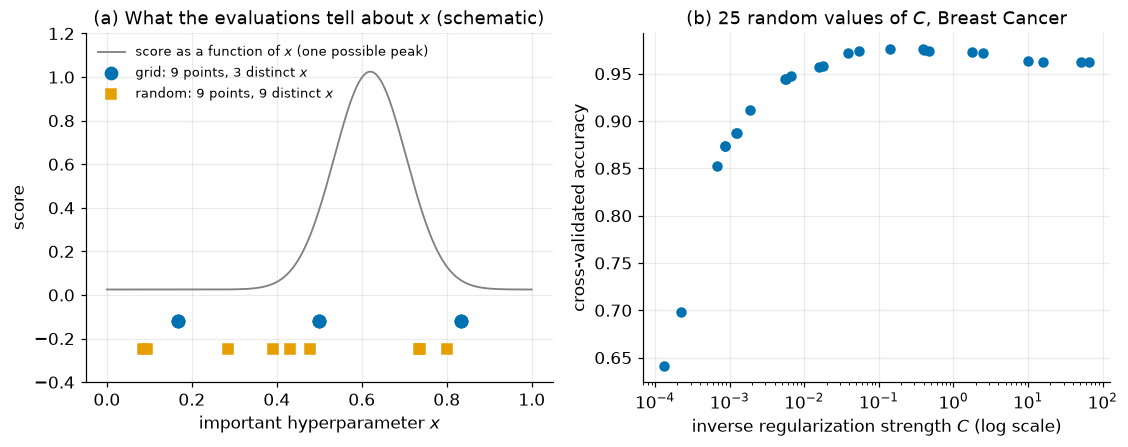

In [19]:
from scipy.stats import loguniform, randint
from sklearn.linear_model import LogisticRegression

pipe_lr = Pipeline([("scale", StandardScaler()), ("logit", LogisticRegression(max_iter=2000))])
rand_lr = RandomizedSearchCV(pipe_lr, {"logit__C": loguniform(1e-4, 1e2)}, n_iter=25, cv=cv_rep, random_state=SEED).fit(X_trbc, y_trbc)
lr_res = pd.DataFrame(rand_lr.cv_results_).sort_values("param_logit__C")
print(f"best C = {rand_lr.best_params_['logit__C']:.4f}, CV accuracy {rand_lr.best_score_:.4f}")

# the same random search for the k-NN pipeline, with a quarter of the budget of the grid
rand_knn = RandomizedSearchCV(pipe_bc, {"knn__n_neighbors": randint(1, 31), "knn__weights": ["uniform", "distance"], "knn__p": [1, 2]},
                              n_iter=15, cv=cv_rep, random_state=SEED).fit(X_trbc, y_trbc)
print(f"k-NN, random search with 15 configurations: CV accuracy {rand_knn.best_score_:.4f} {rand_knn.best_params_}")
print(f"k-NN, grid search with 60 configurations   : CV accuracy {search.best_score_:.4f}")


# Figure 5.6 — random search
def figure_5_6():
    fig, axes = plt.subplots(1, 2, figsize=(10.4, 4.2))
    ax = axes[0]
    xs = np.linspace(0, 1, 200)
    ax.plot(xs, toy_score(xs, 0.5, 0.62), color="gray", linewidth=1.2, label="score as a function of $x$ (one possible peak)")
    ax.plot(grid_pts[:, 0], np.full(9, -0.12), "o", color=BLUE, markersize=8, label="grid: 9 points, 3 distinct $x$")
    r = np.random.default_rng(3).uniform(size=(9, 2))
    ax.plot(r[:, 0], np.full(9, -0.25), "s", color=ORANGE, markersize=7, label="random: 9 points, 9 distinct $x$")
    ax.set(xlabel="important hyperparameter $x$", ylabel="score", ylim=(-0.4, 1.2),
           title="(a) What the evaluations tell about $x$ (schematic)")
    ax.legend(frameon=False, fontsize=8.8, loc="upper left")
    ax = axes[1]
    ax.scatter(lr_res["param_logit__C"].astype(float), lr_res["mean_test_score"], color=BLUE, s=34, zorder=3)
    ax.set_xscale("log")
    ax.set(xlabel="inverse regularization strength $C$ (log scale)", ylabel="cross-validated accuracy",
           title="(b) 25 random values of $C$, Breast Cancer")
    fig.tight_layout()
    plt.show()


figure_5_6()

In the schematic, nine grid evaluations reach a score of 0.692 on average and nine random ones reach 0.816 (the maximum possible is about 1.05): random search wins because it tries nine distinct values of the important hyperparameter against three. On the real problem, 15 random configurations of the $k$-NN pipeline reach a CV accuracy of 0.9703, against 0.9695 for the 60-point grid, at a quarter of the cost (the good region is wide, so a few random draws land in it). Panel (b) shows why the scale matters for a hyperparameter such as $C$: the accuracy is poor for $C$ below $10^{-2}$ (0.64 at the smallest value drawn), and flat near 0.975 for $C$ between 0.03 and 1; the best draw was $C = 0.39$, with a CV accuracy of 0.9757. A uniform draw in $[10^{-4}, 10^{2}]$ would have put almost all of its points above 1 and missed the whole transition region.

### 5.4.3 Nested cross-validation: the winner's curse once more

Grid search reports `best_score_`, the cross-validated score of the winning configuration. This is the best of 60 (or 25, or 1,000) noisy numbers computed on the **same data**, so we are back to Section 5.2.3: **`best_score_` is optimistic**. To estimate the performance of the *whole procedure* ("run the grid search with 5-fold CV and refit the winner") honestly, the selection must be repeated inside an outer loop on data that did not take part in it. This is **nested cross-validation**:

1. split the data into $K_{\text{out}}$ outer folds;
2. for each outer fold: run the **complete** hyperparameter search (with its own inner cross-validation) on the other $K_{\text{out}}-1$ folds, refit the winner on them, and score it on the outer held-out fold, which the search never saw;
3. the average of the $K_{\text{out}}$ outer scores estimates the performance of the procedure.

In scikit-learn nesting is a one-liner: the `GridSearchCV` object is itself an estimator, and it is handed to `cross_val_score`.

### Worked example 5.2 — what nesting costs

With $K_{\text{out}} = 5$ outer folds, $K_{\text{in}} = 5$ inner folds and a grid of 40 configurations, each outer fold needs $40 \times 5 = 200$ fits for the inner search plus one refit of the winner, 201 fits; over the outer folds, $5 \times 201 = \mathbf{1005}$ fits, against $40 \times 5 + 1 = 201$ for the grid search alone. Nesting multiplies the cost by about $K_{\text{out}}$. That is the price of an honest estimate of a tuned procedure, and it is affordable for the fast models of this book; it is the reason why, for slow models, a separate test set (one outer split instead of five) is the usual compromise.

**The experiment** (this cell fits tens of thousands of small models and takes a couple of minutes). We take $n = 60$ patients from the Breast Cancer data (a small sample, where optimism is largest) and a grid of 32 configurations of the standardized $k$-NN (8 values of $k$, 2 weightings, 2 distances). We compare, over 24 repetitions with different samples:

- the **non-nested** score: `best_score_` of the grid search (5-fold inner CV);
- the **nested** score: 5-fold outer CV around the same grid search;
- the **actual** accuracy of the refitted winner on the other 509 patients (almost exact).

We do it twice. With the **real labels**, and with **coin-flip labels** (the features are real, the labels are fair coin flips, *flagged simulation*): there nothing can be learned, the true accuracy of every configuration is exactly 0.5, and any score above 0.5 is pure optimism.

           non-nested (best_score_)        nested CV        actual accuracy       
                               mean    std      mean    std            mean    std
labels                                                                            
coin flips                    0.588  0.054     0.515  0.078           0.502  0.023
real                          0.958  0.024     0.937  0.027           0.934  0.012

optimism of best_score_ (non-nested minus actual), mean over repetitions:
labels
coin flips    0.086
real          0.023
optimism of the nested score (nested minus actual):
labels
coin flips    0.013
real          0.002


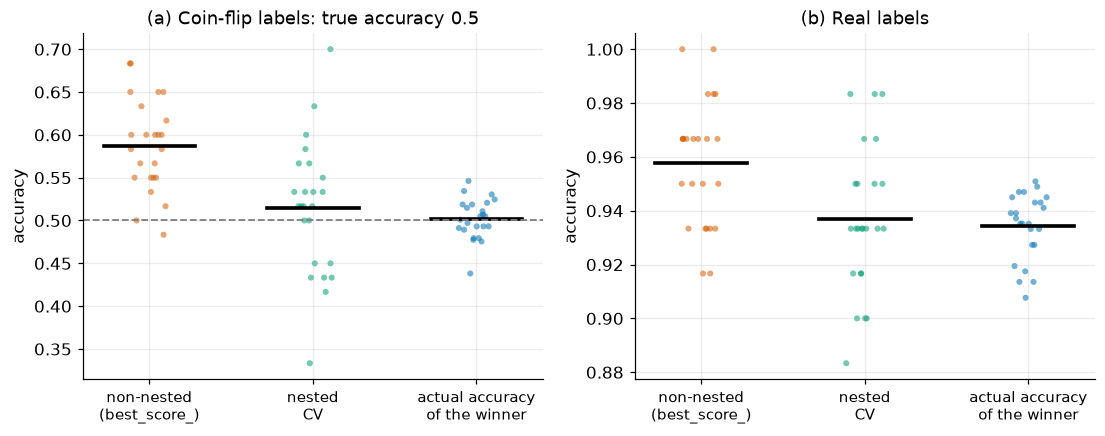

In [20]:
import time

pipe_small = Pipeline([("scale", StandardScaler()), ("knn", KNeighborsClassifier())])
grid_small = {"knn__n_neighbors": [1, 3, 5, 7, 9, 11, 13, 15], "knn__weights": ["uniform", "distance"], "knn__p": [1, 2]}


def nested_vs_nonnested(n=60, n_rep=24, seed=SEED):
    rng = np.random.default_rng(seed)
    rows = []
    for rep in range(n_rep):
        perm = rng.permutation(len(y_bc))
        s, t = perm[:n], perm[n:]
        for labels in ("real", "coin flips"):
            y_s = y_bc[s] if labels == "real" else rng.integers(0, 2, size=n)
            y_t = y_bc[t] if labels == "real" else rng.integers(0, 2, size=len(t))
            inner = KFold(5, shuffle=True, random_state=rep)
            gs = GridSearchCV(pipe_small, grid_small, cv=inner).fit(X_bc[s], y_s)
            nested = cross_val_score(GridSearchCV(pipe_small, grid_small, cv=KFold(5, shuffle=True, random_state=rep)),
                                     X_bc[s], y_s, cv=KFold(5, shuffle=True, random_state=100 + rep)).mean()
            rows.append({"labels": labels, "non-nested (best_score_)": gs.best_score_, "nested CV": nested,
                         "actual accuracy": gs.score(X_bc[t], y_t)})
    return pd.DataFrame(rows)


t0 = time.perf_counter()
nest = nested_vs_nonnested()
summary = nest.groupby("labels").agg(["mean", "std"]).round(3)
print(summary.to_string())
print("\noptimism of best_score_ (non-nested minus actual), mean over repetitions:")
print((nest["non-nested (best_score_)"] - nest["actual accuracy"]).groupby(nest["labels"]).mean().round(3).to_string())
print("optimism of the nested score (nested minus actual):")
print((nest["nested CV"] - nest["actual accuracy"]).groupby(nest["labels"]).mean().round(3).to_string())


# Figure 5.7 — non-nested against nested estimates
def figure_5_7():
    fig, axes = plt.subplots(1, 2, figsize=(10.2, 4.1), sharey=False)
    cols = ["non-nested (best_score_)", "nested CV", "actual accuracy"]
    colors = [VERMILION, GREEN, BLUE]
    for ax, labels, title in zip(axes, ["coin flips", "real"], ["(a) Coin-flip labels: true accuracy 0.5", "(b) Real labels"]):
        sub = nest[nest["labels"] == labels]
        for i, (c, color) in enumerate(zip(cols, colors)):
            ax.scatter(np.full(len(sub), i) + np.random.default_rng(i).uniform(-0.12, 0.12, len(sub)), sub[c], color=color,
                       s=16, alpha=0.55, edgecolor="none")
            ax.plot([i - 0.28, i + 0.28], [sub[c].mean()] * 2, color="black", linewidth=2.4)
        if labels == "coin flips":
            ax.axhline(0.5, color="gray", linestyle="--", linewidth=1.2)
        ax.set_xticks(range(3))
        ax.set_xticklabels(["non-nested\n(best_score_)", "nested\nCV", "actual accuracy\nof the winner"], fontsize=9.5)
        ax.set(ylabel="accuracy", title=title)
    fig.tight_layout()
    plt.show()


figure_5_7()

**With coin-flip labels**, the `best_score_` of the grid search averages 0.588 although the true accuracy of every configuration is 0.5 (the refitted winner scores 0.502 on fresh data): the search manufactured 8.6 points of apparent skill out of nothing: the score of the best of 32 noisy values, each computed on 60 examples. The nested estimate averages 0.515, within 1.3 points of the truth. **With the real labels** the same pattern is milder, because there is a real signal: `best_score_` is 0.958, the nested estimate is 0.937 and the actual accuracy is 0.934, so the optimism of the non-nested score is 2.3 points and that of the nested score 0.2 points.

Four remarks. (1) The optimism of `best_score_` is large when the sample is small, the grid is large and the signal is weak, and it shrinks as $n$ grows, exactly as in Section 5.2.3. (2) The nested estimate is nearly **unbiased but noisy**: its spread over the repetitions is 0.078 for the coin flips and 0.027 for the real labels, because each outer fold contains only 12 patients. (3) It estimates the performance of the **procedure**, not of one configuration: different outer folds may well select different winners, and that is allowed. (4) The final model is not produced by the nested loop. The nested loop answers "how good is *this way of tuning and fitting*?", and is the right tool to compare procedures (for instance a tuned $k$-NN against a tuned logistic regression, or tuning against not tuning). The model that we deploy is obtained by running the inner procedure, once, on all the training data.

### 5.4.4 Practical rules for tuning

- **Put the search on the right scale.** Linear grids for counts and depths, logarithmic for strengths, rates and scale parameters. If the best value lies on the **edge** of the range, extend the range.
- **Go coarse to fine, and spend by importance.** A first random search over wide ranges shows which hyperparameters matter; a second, narrower one refines them.
- **Do not over-tune.** If dozens of settings are tied within the noise (Section 5.4.1), picking the top one buys nothing; apply the one-standard-error rule, or choose the cheapest or the most interpretable.
- **Tune inside the pipeline** (scalers, imputers and selectors are fitted on the training folds only), and **fix the seed** of every random component so that a result can be reproduced.
- **Report the right number.** After tuning, evaluate **once** on the untouched test set; if there is no test set, report the nested CV score. Never report `best_score_` as the performance.
- **Sequential methods exist.** Successive halving (`HalvingRandomSearchCV`) discards poor configurations after a small budget; Bayesian optimization (for instance the Optuna library) uses past results to choose the next trial. They save compute on large problems, but the discipline of this chapter (inner loop for the choice, outer loop or test set for the report) is the same.

## 5.5 Is one model really better than another?

After tuning we often hold two candidates, say $k$-NN and logistic regression, and ask whether the difference between their scores is real. Section 5.2.2 said that a difference of three points on 100 examples is no evidence, and Worked example 5.1 treated the two accuracies as independent. They are not: both models are evaluated on the **same examples**, and two models tend to make the same mistakes on the same hard cases. Using this pairing makes the comparison sharper.

### 5.5.1 Two classifiers on one test set: McNemar's test

For each test example record whether A and B are right. Only two kinds of examples carry information about *which model is better*: those that A gets right and B gets wrong (call their number $b$), and those that A gets wrong and B gets right ($c$). The examples where both are right, or both are wrong, say nothing about the difference. If the two models had the same error rate, each discordant example would be equally likely to fall in either group, so $b \sim \text{Binomial}(b + c, \tfrac12)$, and the exact **McNemar test** has the two-sided $p$-value
$$
p = \min\Big(1,\ 2\,\mathbb{P}\big(\text{Binomial}(b+c, \tfrac12) \le \min(b, c)\big)\Big).
$$

### Worked example 5.3 — McNemar by hand

On a test set of 200 examples, A is right on 180 (90%) and B on 186 (93%). The cross-tabulation shows $b = 4$ examples where A is right and B wrong, and $c = 10$ where A is wrong and B right (indeed $c - b = 6 = 186 - 180$). Then
$$
\mathbb{P}\big(\text{Bin}(14, \tfrac12) \le 4\big) = \frac{\binom{14}{0} + \binom{14}{1} + \binom{14}{2} + \binom{14}{3} + \binom{14}{4}}{2^{14}} = \frac{1 + 14 + 91 + 364 + 1001}{16384} = \frac{1471}{16384} = 0.0898,
$$
so $p = 2 \times 0.0898 = 0.180$: **not significant**, in spite of three points of difference. (Only 14 of the 200 examples are discordant: that is the data on which the comparison rests.)

In [21]:
from math import comb

b_, c_ = 4, 10
p_hand = min(1.0, 2 * sum(comb(b_ + c_, i) for i in range(0, min(b_, c_) + 1)) / 2 ** (b_ + c_))
p_scipy = stats.binomtest(min(b_, c_), b_ + c_, 0.5).pvalue
print(f"by hand: {p_hand:.4f}   scipy.stats.binomtest: {p_scipy:.4f}")

# The same test on a real pair of models, fixed in advance: 5-NN and logistic regression, no tuning.
# We use a new split of the 569 patients (40% for testing), so that the test set of Section 5.4.1 stays untouched.
X_a, X_b, y_a, y_b = train_test_split(X_bc, y_bc, test_size=0.4, random_state=7, stratify=y_bc)
model_a = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)).fit(X_a, y_a)
model_b = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(X_a, y_a)
right_a, right_b = model_a.predict(X_b) == y_b, model_b.predict(X_b) == y_b
b_obs, c_obs = int(np.sum(right_a & ~right_b)), int(np.sum(~right_a & right_b))
print(f"test set of {len(y_b)} patients: accuracy of 5-NN {right_a.mean():.4f}, of logistic regression {right_b.mean():.4f}")
print(f"both right: {int(np.sum(right_a & right_b))}, both wrong: {int(np.sum(~right_a & ~right_b))}, "
      f"A right and B wrong: {b_obs}, A wrong and B right: {c_obs}")
print(f"McNemar p-value: {stats.binomtest(min(b_obs, c_obs), b_obs + c_obs, 0.5).pvalue:.3f}")

by hand: 0.1796   scipy.stats.binomtest: 0.1796
test set of 228 patients: accuracy of 5-NN 0.9693, of logistic regression 0.9825
both right: 218, both wrong: 1, A right and B wrong: 3, A wrong and B right: 6
McNemar p-value: 0.508


For a real pair, we compare a 5-NN and a logistic regression (both fixed in advance, nothing tuned) on a new split of the Breast Cancer data. On the 228 test patients the accuracies are 0.969 and 0.982, but the two models disagree on only nine patients, three in favor of the $k$-NN and six in favor of the logistic regression: $p = 0.51$. A difference of 1.3 points, three patients, is exactly what chance produces. McNemar's test is fast and needs only the predictions, but its power is limited by the number of discordant examples, and **a test set with few discordant examples cannot rank two models**, however many examples it contains in total.

### 5.5.2 Comparing with resampling: why the naive $t$-test is wrong

A single test set of a few dozen examples has little power, so a tempting alternative is to repeat the comparison on many random splits of the sample, $J = 20$ for instance, compute the difference of accuracies $d_j$ on each, and run a paired $t$-test on the $J$ values: $t = \bar d / \sqrt{s_d^2/J}$ with $J - 1$ degrees of freedom. **This test is wrong**, and wrong in a dangerous direction (it rejects too often). The $d_j$ are not independent: all the training sets are drawn from the same sample, they overlap heavily, and so do the test sets, and any peculiarity of the sample (an unlucky label pattern, an influential point) pushes *all* the $d_j$ the same way. The variance of the mean of $J$ correlated values does not go to zero as $J$ grows: if the correlation between two splits is $\rho$, then $\operatorname{Var}(\bar d) = \big(\tfrac1J + \tfrac{\rho}{1-\rho}\big)\sigma_d^2$, and for random splits $\rho \approx n_{\text{test}}/(n_{\text{test}} + n_{\text{train}})$, hence $\tfrac{\rho}{1-\rho} \approx n_{\text{test}}/n_{\text{train}}$. Nadeau and Bengio (2003) proposed the **corrected resampled $t$-test**, which keeps the same statistic with the right variance:
$$
t = \frac{\bar d}{\sqrt{\big(\tfrac1J + \tfrac{n_{\text{test}}}{n_{\text{train}}}\big)\, s_d^2}}, \qquad J - 1 \text{ degrees of freedom.}
$$
Note that the correction is *not* removed by taking more splits: with $J \to \infty$ the factor tends to $n_{\text{test}}/n_{\text{train}}$, which expresses the fact that all the splits live in the same finite sample.

We measure how the tests behave: $k$-NN (5 neighbors) against logistic regression, on 200 patients drawn from Breast Cancer, 20 random splits (two thirds for training), repeated over 200 independent samples. Two cases. With **coin-flip labels** (*flagged simulation*) the two models have exactly the same true accuracy, 0.5, so every rejection is a false alarm, and the rejection rate at the 5% level should be 5%. With the **real labels** the logistic regression is slightly better, so rejections are (partly) correct.

    labels  mean difference (k-NN minus logistic)  rejects at 5%: naive  rejects at 5%: corrected  rejects at 5%: McNemar (1 split)
coin flips                                 -0.001                 0.435                     0.005                             0.040
      real                                 -0.018                 0.755                     0.050                             0.005


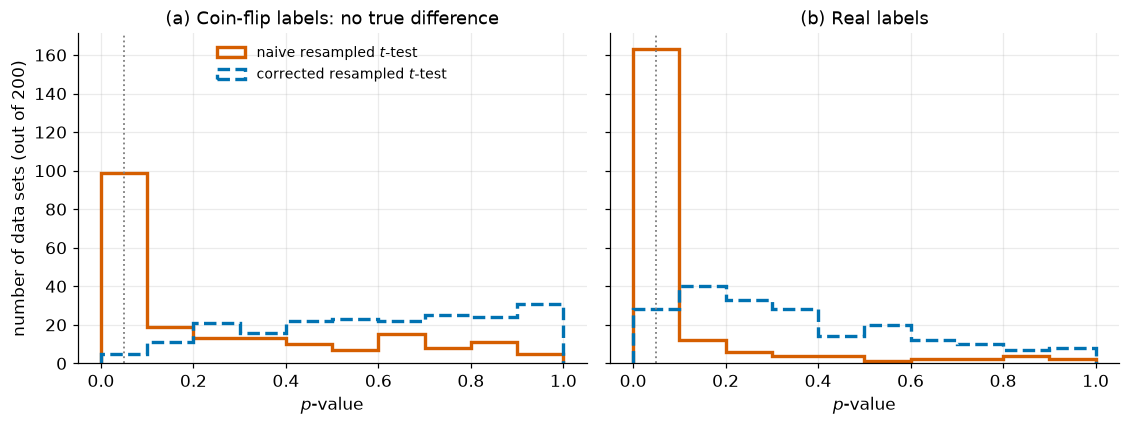

In [22]:
from sklearn.model_selection import ShuffleSplit


def paired_tests(labels, n_rep=200, J=20, n=200, seed=SEED):
    """p-values of the naive and of the corrected resampled t-test, and of McNemar on the first split."""
    rng = np.random.default_rng(seed)
    out = []
    for rep in range(n_rep):
        idx = rng.choice(len(y_bc), size=n, replace=False)
        X_s = X_bc[idx]
        y_s = rng.integers(0, 2, size=n) if labels == "coin flips" else y_bc[idx]
        d, mc = [], None
        for j, (tr, te) in enumerate(ShuffleSplit(n_splits=J, test_size=1 / 3, random_state=rep).split(X_s)):
            a = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)).fit(X_s[tr], y_s[tr])
            b = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(X_s[tr], y_s[tr])
            ra, rb = a.predict(X_s[te]) == y_s[te], b.predict(X_s[te]) == y_s[te]
            d.append(ra.mean() - rb.mean())
            if j == 0:
                n_ab, n_ba = int(np.sum(ra & ~rb)), int(np.sum(~ra & rb))
                mc = stats.binomtest(min(n_ab, n_ba), n_ab + n_ba, 0.5).pvalue if n_ab + n_ba else 1.0
        d = np.array(d)
        var = d.var(ddof=1)
        t_naive = d.mean() / np.sqrt(var / J)
        t_corr = d.mean() / np.sqrt((1 / J + len(te) / len(tr)) * var)
        out.append({"naive": 2 * stats.t.sf(abs(t_naive), J - 1), "corrected": 2 * stats.t.sf(abs(t_corr), J - 1),
                    "McNemar (1 split)": mc, "mean difference": d.mean()})
    return pd.DataFrame(out)


pvals = {lab: paired_tests(lab) for lab in ("coin flips", "real")}
rows = []
for lab, df in pvals.items():
    rows.append({"labels": lab, "mean difference (k-NN minus logistic)": df["mean difference"].mean(),
                 **{f"rejects at 5%: {c}": float((df[c] < 0.05).mean()) for c in ["naive", "corrected", "McNemar (1 split)"]}})
print(pd.DataFrame(rows).round(3).to_string(index=False))


# Figure 5.8 — distribution of the p-values
def figure_5_8():
    fig, axes = plt.subplots(1, 2, figsize=(10.4, 4.0), sharey=True)
    bins = np.linspace(0, 1, 11)
    for ax, lab, title in zip(axes, ["coin flips", "real"], ["(a) Coin-flip labels: no true difference", "(b) Real labels"]):
        ax.hist(pvals[lab]["naive"], bins=bins, histtype="step", linewidth=2.2, color=VERMILION, linestyle="-", label="naive resampled $t$-test")
        ax.hist(pvals[lab]["corrected"], bins=bins, histtype="step", linewidth=2.2, color=BLUE, linestyle="--", label="corrected resampled $t$-test")
        ax.axvline(0.05, color="gray", linewidth=1.2, linestyle=":")
        ax.set(xlabel="$p$-value", title=title)
    axes[0].set_ylabel("number of data sets (out of 200)")
    axes[0].legend(frameon=False, fontsize=9.3, loc="upper center")
    fig.tight_layout()
    plt.show()


figure_5_8()

The table and Figure 5.8 give the verdict. With **coin-flip labels** there is no difference to find, so a valid test should reject in about 5% of the data sets. The naive resampled $t$-test rejects in **43.5%** of them: its $p$-values pile up near zero (panel (a)). The corrected test rejects in 0.5% (it is valid, in fact a little conservative), and its $p$-values are spread over $[0, 1]$ as they should be under the null. McNemar on a single split rejects in 4.0%, which is also valid.

With the **real labels**, where the logistic regression is better by 1.8 points on average, the naive test "detects" the difference in 75.5% of the data sets, but we know that it would "detect" a difference in 43.5% of the cases where there is none: its rejections are worth little. The corrected test rejects in 5.0% of the data sets and McNemar on a single split of 67 test patients in 0.5%: with 200 patients, a true difference of 1.8 points is **beyond reach**, and no resampling scheme can change this, because all the splits are drawn from the same 200 patients. The remedy for low power is more data, not a more lenient test.

:::{admonition} Key idea — differences within the noise
:class: tip
Two models whose scores differ by less than the noise of the comparison should be treated as **equivalent**, and the choice between them made on other grounds: simplicity, speed, interpretability, robustness, cost of deployment. A score difference deserves a decision only when a paired test that accounts for the dependence between splits says so. When you report a comparison, report the difference and its uncertainty, not just the two means.
:::

## 5.6 Measuring performance: which number?

So far "performance" has meant accuracy. Accuracy is the right number only when all errors cost the same and the classes are of comparable size. This section collects the measures that tell more, and the way to choose among them. The running example is the Breast Cancer data with the class that matters, **malignant**, as the *positive* class (in scikit-learn's encoding the malignant tumors have label 0, so we flip the labels: `y_m = 1` means malignant). To avoid touching the test set of Section 5.4.1, all numbers in Sections 5.6.1 to 5.6.3 are computed from **out-of-fold predictions**: a 10-fold stratified cross-validation in which every patient is predicted by a model that has never seen him or her.

### 5.6.1 The confusion matrix, and what accuracy hides

For a binary classifier the outcomes of the predictions are counted in the **confusion matrix**:

| | predicted positive | predicted negative |
|---|---|---|
| **actually positive** | true positives (TP) | false negatives (FN) |
| **actually negative** | false positives (FP) | true negatives (TN) |

and the usual summary numbers are ratios of its entries:

| Name | Formula | Question it answers |
|---|---|---|
| accuracy | $\dfrac{TP+TN}{TP+FP+FN+TN}$ | how often is the classifier right? |
| **recall** (sensitivity, true-positive rate) | $\dfrac{TP}{TP+FN}$ | of the truly positive cases, how many do we catch? |
| **specificity** (true-negative rate) | $\dfrac{TN}{TN+FP}$ | of the truly negative cases, how many do we correctly clear? |
| false-positive rate | $\dfrac{FP}{FP+TN} = 1 - \text{specificity}$ | of the negative cases, how many do we falsely flag? |
| **precision** (positive predictive value) | $\dfrac{TP}{TP+FP}$ | of the cases we flag, how many are truly positive? |
| $F_1$ | $\dfrac{2\,\text{precision}\cdot\text{recall}}{\text{precision}+\text{recall}}$ | harmonic mean of precision and recall |

The $F_1$ score is the harmonic mean, which is dominated by the smaller of the two numbers, so a classifier cannot compensate a very low recall with a high precision. The general **$F_\beta$** score, $F_\beta = (1+\beta^2)\,\dfrac{\text{precision}\cdot\text{recall}}{\beta^2\,\text{precision}+\text{recall}}$, weights recall $\beta$ times as much as precision ($\beta = 2$ favors recall, $\beta = 0.5$ favors precision). **Precision and recall answer different questions**, and which one matters depends on the cost of each kind of mistake: missing a malignant tumor (FN) and sending a healthy patient to further tests (FP) are not equally bad.

We compute all of these by hand from the confusion matrix of the out-of-fold predictions, compare them with scikit-learn's functions, and add a **baseline** that ignores the features and always predicts the majority class.

In [23]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import (accuracy_score, average_precision_score, brier_score_loss, confusion_matrix, f1_score,
                             precision_recall_curve, precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.dummy import DummyClassifier
from sklearn.calibration import calibration_curve

y_m = 1 - y_bc                                   # 1 = malignant (the positive class), 0 = benign
print(f"{int(y_m.sum())} malignant and {int((1 - y_m).sum())} benign tumors: prevalence of the positive class {y_m.mean():.3f}")

cv10 = StratifiedKFold(10, shuffle=True, random_state=SEED)
candidates = {
    "logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "5-NN": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    "baseline: majority class": DummyClassifier(strategy="most_frequent"),
}
oof = {name: cross_val_predict(model, X_bc, y_m, cv=cv10, method="predict_proba")[:, 1] for name, model in candidates.items()}


def confusion_counts(y_true, y_pred):
    tp = int(np.sum((y_pred == 1) & (y_true == 1))); fn = int(np.sum((y_pred == 0) & (y_true == 1)))
    fp = int(np.sum((y_pred == 1) & (y_true == 0))); tn = int(np.sum((y_pred == 0) & (y_true == 0)))
    return tp, fn, fp, tn


def summary_measures(y_true, y_pred):
    tp, fn, fp, tn = confusion_counts(y_true, y_pred)
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn)
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return {"accuracy": (tp + tn) / len(y_true), "recall": recall, "specificity": tn / (tn + fp), "precision": precision, "F1": f1}


pred = {name: (p >= 0.5).astype(int) for name, p in oof.items()}
tp, fn, fp, tn = confusion_counts(y_m, pred["logistic regression"])
print("\nconfusion matrix of logistic regression at the threshold 0.5 (out-of-fold predictions):")
print(pd.DataFrame([[tp, fn], [fp, tn]], index=["actually malignant", "actually benign"],
                   columns=["predicted malignant", "predicted benign"]).to_string())
table = pd.DataFrame({name: summary_measures(y_m, p) for name, p in pred.items()}).T
print("\n" + table.round(4).to_string())
ref = pred["logistic regression"]
print("\nagreement with scikit-learn (logistic regression):",
      np.isclose(accuracy_score(y_m, ref), table.loc["logistic regression", "accuracy"]),
      np.isclose(recall_score(y_m, ref), table.loc["logistic regression", "recall"]),
      np.isclose(precision_score(y_m, ref), table.loc["logistic regression", "precision"]),
      np.isclose(f1_score(y_m, ref), table.loc["logistic regression", "F1"]))

212 malignant and 357 benign tumors: prevalence of the positive class 0.373



confusion matrix of logistic regression at the threshold 0.5 (out-of-fold predictions):
                    predicted malignant  predicted benign
actually malignant                  202                10
actually benign                       4               353

                          accuracy  recall  specificity  precision      F1
logistic regression         0.9754  0.9528       0.9888     0.9806  0.9665
5-NN                        0.9701  0.9292       0.9944     0.9899  0.9586
baseline: majority class    0.6274  0.0000       1.0000     0.0000  0.0000

agreement with scikit-learn (logistic regression): True True True True


The logistic regression makes 4 false-positive and 10 false-negative errors: its recall is 0.953 and its precision 0.981. The 5-NN has the *opposite* balance, a higher precision (0.990) and a lower recall (0.929): at the same threshold it misses 15 of the 212 malignant tumors against 10 for the logistic regression, and raises 2 false alarms against 4. Which of the two is "better" depends on what a missed tumor costs relative to a false alarm, and **accuracy cannot express this** (0.975 against 0.970). The baseline makes the other point: by always answering "benign" it reaches an accuracy of 0.627, the proportion of benign tumors, and detects *no* malignant tumor at all (recall 0). Every number in this chapter should be read next to its baseline, and for a problem where one class matters more, accuracy should be replaced or supplemented by recall and precision. The last line of the output confirms that our formulas agree with scikit-learn's functions.

### Worked example 5.4 — what does a "positive" mean?

A screening test has sensitivity (recall) 95% and specificity 90%. It is used in a population in which 1% of the people have the disease. What is the precision of a positive result? Take 10,000 people: 100 are ill and 9,900 are healthy. The test flags $0.95 \times 100 = 95$ of the ill ($TP = 95$, $FN = 5$) and $0.10 \times 9{,}900 = 990$ of the healthy ($FP = 990$, $TN = 8{,}910$). Hence
$$
\text{precision} = \frac{TP}{TP + FP} = \frac{95}{95 + 990} = 0.0876, \qquad \text{accuracy} = \frac{95 + 8910}{10000} = 0.9005.
$$
Only **8.8%** of the positive results are real, even though the test is "95% sensitive and 90% specific" and 90% accurate; and a classifier that always says "healthy" would be 99% accurate. This is Bayes' rule at work (Worked example 2.3): the precision depends not only on the test but also on the **prevalence** $\pi$ of the disease,
$$
\text{precision} = \frac{\pi\cdot\text{recall}}{\pi\cdot\text{recall} + (1-\pi)\cdot\text{FPR}},
$$
a formula that we use again in Section 5.6.3.

In [24]:
pi_, recall_, spec_ = 0.01, 0.95, 0.90
tp_, fp_ = pi_ * recall_, (1 - pi_) * (1 - spec_)
print(f"precision = {tp_ / (tp_ + fp_):.4f}")
print(f"accuracy  = {tp_ + (1 - pi_) * spec_:.4f}   accuracy of 'always healthy' = {1 - pi_:.2f}")

precision = 0.0876
accuracy  = 0.9005   accuracy of 'always healthy' = 0.99


### 5.6.2 Scores, thresholds, the ROC curve and the AUC

Most classifiers do not output a label but a **score**, a number that is larger when the classifier is more confident that the example is positive: a probability for logistic regression, the fraction of positive neighbors for $k$-NN. The label comes from a **threshold** $t$: predict positive when the score is at least $t$. The value $t = 0.5$ is only a convention. Moving $t$ trades recall for false alarms: a low threshold flags many cases (high recall, many false positives), a high threshold flags few.

The **ROC curve** (receiver operating characteristic) plots, as the threshold sweeps from $+\infty$ to $-\infty$, the true-positive rate $\text{TPR}(t) = \mathbb{P}(S \ge t \mid y = 1)$ against the false-positive rate $\text{FPR}(t) = \mathbb{P}(S \ge t \mid y = 0)$, where $S$ is the score. It starts at $(0, 0)$ (nothing is flagged) and ends at $(1, 1)$ (everything is). A useless classifier, whose score is independent of the label, follows the diagonal; a perfect one goes through the corner $(0, 1)$. The **area under the curve** (AUC) summarizes the whole curve in one number, with a remarkably concrete meaning.

**Proposition 5.1 (the AUC is a probability).** Let $S^+$ and $S^-$ be the scores of a randomly chosen positive and a randomly chosen negative example, drawn independently. Then
$$
\text{AUC} = \mathbb{P}\big(S^+ > S^-\big) + \tfrac12\,\mathbb{P}\big(S^+ = S^-\big).
$$

:::{admonition} Proof
:class: dropdown
Let $F^-$ be the distribution function of $S^-$, so that $\text{FPR}(t) = 1 - F^-(t^-)$ and $\text{TPR}(t) = \mathbb{P}(S^+ \ge t)$. Suppose first that the scores have densities. Then $d\,\text{FPR}(t) = -f^-(t)\,dt$, and the area under the curve, traversed with the threshold decreasing from $+\infty$ to $-\infty$, is
$$
\text{AUC} = \int_{0}^{1} \text{TPR}\; d\text{FPR} = \int_{-\infty}^{\infty} \mathbb{P}(S^+ \ge t)\, f^-(t)\, dt = \mathbb{P}(S^+ \ge S^-),
$$
because the last integral averages the probability that $S^+$ exceeds the value $t$ over the random value $t = S^-$ (here $S^+$ and $S^-$ are independent). With ties, the empirical ROC curve joins the points of a block of tied scores with a straight segment, and the trapezoid under that segment counts each tied pair as one half. $\square$
:::

In words: **if you pick one malignant and one benign tumor at random, the AUC is the probability that the classifier gives the malignant one the higher score.** An AUC of 0.5 is chance, 1 is perfect ranking. It does not depend on any threshold, nor on the prevalence of the classes, nor on the scale of the scores (any increasing transformation of the scores leaves it unchanged); it does *not* say whether the scores are calibrated probabilities (Section 5.6.4). We implement the curve and the AUC in three ways: the trapezoid rule on the ROC points, the definition as a fraction of (positive, negative) pairs, and scikit-learn.

In [25]:
def roc_points(y_true, score):
    """ROC curve: (FPR, TPR, threshold) for every distinct score, thresholds from high to low."""
    order = np.argsort(-score, kind="stable")
    y_sorted, s_sorted = y_true[order], score[order]
    last_of_block = np.r_[np.where(np.diff(s_sorted))[0], len(y_true) - 1]    # last index of each block of tied scores
    tp = np.cumsum(y_sorted)[last_of_block]
    fp = (last_of_block + 1) - tp
    n_pos, n_neg = y_true.sum(), len(y_true) - y_true.sum()
    return np.r_[0, fp / n_neg], np.r_[0, tp / n_pos], np.r_[np.inf, s_sorted[last_of_block]]


def auc_trapezoid(fpr, tpr):
    return float(np.sum(np.diff(fpr) * (tpr[1:] + tpr[:-1]) / 2))


def auc_pairs(y_true, score):
    pos, neg = score[y_true == 1], score[y_true == 0]
    return float(np.mean(pos[:, None] > neg[None, :]) + 0.5 * np.mean(pos[:, None] == neg[None, :]))


rows = []
for name in ["logistic regression", "5-NN"]:
    fpr, tpr, thr = roc_points(y_m, oof[name])
    rows.append({"model": name, "distinct scores": len(np.unique(oof[name])), "AUC (trapezoid)": auc_trapezoid(fpr, tpr),
                 "AUC (pairs)": auc_pairs(y_m, oof[name]), "AUC (scikit-learn)": roc_auc_score(y_m, oof[name])})
print(pd.DataFrame(rows).round(5).to_string(index=False))

# operating points of the logistic regression at several thresholds
fpr, tpr, thr = roc_points(y_m, oof["logistic regression"])
rows = []
for t in [0.9, 0.5, 0.1, 0.02]:
    pred_t = (oof["logistic regression"] >= t).astype(int)
    tp_, fn_, fp_, tn_ = confusion_counts(y_m, pred_t)
    rows.append({"threshold": t, "TPR (recall)": tp_ / (tp_ + fn_), "FPR": fp_ / (fp_ + tn_), "precision": tp_ / (tp_ + fp_), "FP": fp_, "FN": fn_})
print("\n" + pd.DataFrame(rows).round(4).to_string(index=False))

              model  distinct scores  AUC (trapezoid)  AUC (pairs)  AUC (scikit-learn)
logistic regression              568          0.99466      0.99466             0.99466
               5-NN                6          0.98622      0.98622             0.98622

 threshold  TPR (recall)    FPR  precision  FP  FN
      0.90        0.8726 0.0000     1.0000   0  27
      0.50        0.9528 0.0112     0.9806   4  10
      0.10        0.9858 0.1036     0.8496  37   3
      0.02        0.9953 0.2241     0.7251  80   1


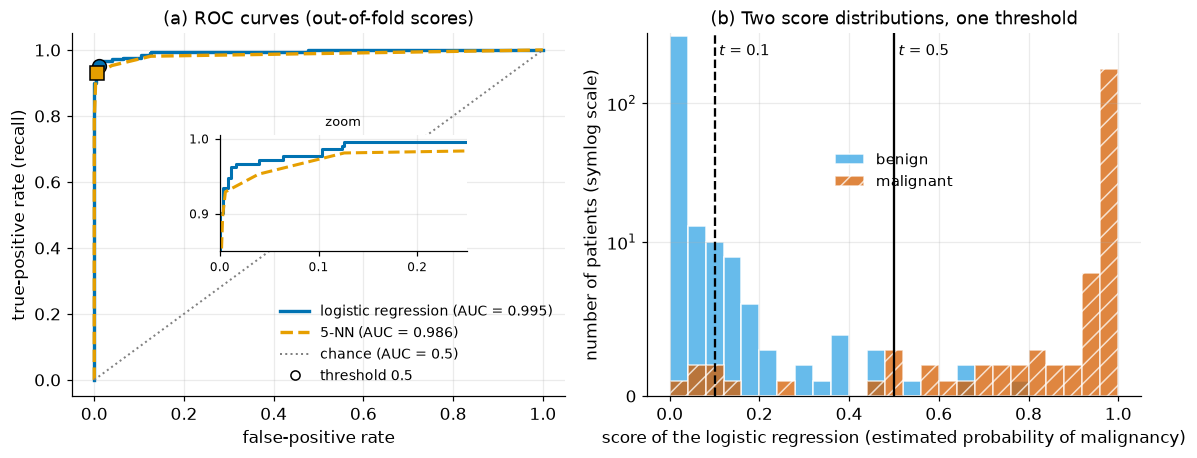

In [26]:
# Figure 5.9 — ROC curves and the score distributions behind them
def figure_5_9():
    fig, axes = plt.subplots(1, 2, figsize=(10.6, 4.3))
    ax = axes[0]
    styles = {"logistic regression": (BLUE, "-", "o"), "5-NN": (ORANGE, "--", "s")}
    for name, (color, ls, marker) in styles.items():
        f, t, _ = roc_points(y_m, oof[name])
        ax.plot(f, t, color=color, linestyle=ls, linewidth=2.2, label=f"{name} (AUC = {auc_trapezoid(f, t):.3f})")
        p05 = (oof[name] >= 0.5).astype(int)
        tp_, fn_, fp_, tn_ = confusion_counts(y_m, p05)
        ax.plot([fp_ / (fp_ + tn_)], [tp_ / (tp_ + fn_)], marker=marker, markersize=9, color=color, markeredgecolor="black",
                linestyle="none")
    ax.plot([0, 1], [0, 1], color="gray", linestyle=":", linewidth=1.3, label="chance (AUC = 0.5)")
    ax.plot([], [], marker="o", color="white", markeredgecolor="black", linestyle="none", label="threshold 0.5")
    ax.set(xlabel="false-positive rate", ylabel="true-positive rate (recall)", title="(a) ROC curves (out-of-fold scores)")
    ax.legend(frameon=False, fontsize=9.3, loc="lower right")
    zoom = ax.inset_axes([0.3, 0.4, 0.5, 0.32])                  # a zoom on the upper-left corner, where the curves differ
    for name, (color, ls, marker) in styles.items():
        f, t, _ = roc_points(y_m, oof[name])
        zoom.plot(f, t, color=color, linestyle=ls, linewidth=2)
    zoom.set(xlim=(0, 0.25), ylim=(0.85, 1.005), title="zoom", xticks=[0, 0.1, 0.2], yticks=[0.9, 1.0])
    zoom.tick_params(labelsize=8)
    zoom.title.set_fontsize(8.5)
    ax = axes[1]
    bins = np.linspace(0, 1, 26)
    ax.hist(oof["logistic regression"][y_m == 0], bins=bins, color=SKY, alpha=0.9, label="benign", edgecolor="white")
    ax.hist(oof["logistic regression"][y_m == 1], bins=bins, color=VERMILION, alpha=0.75, label="malignant", edgecolor="white", hatch="//")
    for t, ls in [(0.5, "-"), (0.1, "--")]:
        ax.axvline(t, color="black", linestyle=ls, linewidth=1.5)
        ax.text(t + 0.01, 0.97, f"$t$ = {t}", fontsize=9.5, va="top", transform=ax.get_xaxis_transform())
    ax.set_yscale("symlog", linthresh=10)
    ax.set(xlabel="score of the logistic regression (estimated probability of malignancy)", ylabel="number of patients (symlog scale)",
           title="(b) Two score distributions, one threshold")
    ax.legend(frameon=False, fontsize=9.5, loc="center", bbox_to_anchor=(0.5, 0.62))
    fig.tight_layout()
    plt.show()


figure_5_9()

The three computations of the AUC agree to five decimals: 0.99466 for the logistic regression and 0.98622 for the 5-NN. The $k$-NN scores take only six distinct values (the fraction of malignant tumors among five neighbors is 0, 0.2, ..., 1), so its ROC curve is a staircase with a handful of corners, while the logistic regression has 568 distinct scores among 569 patients. In panel (a) of Figure 5.9 both curves hug the upper-left corner; the two classifiers differ by about one point of AUC.

The table shows how the threshold moves the operating point along the curve. At $t = 0.9$ no benign tumor is flagged but 27 malignant ones are missed (recall 0.873); at $t = 0.5$ there are 10 misses and 4 false alarms; at $t = 0.1$, 3 misses and 37 false alarms; at $t = 0.02$ only one malignant tumor is missed, but 80 healthy patients are flagged. Panel (b) shows why: the scores of the two classes overlap in the middle, and a threshold cuts both distributions at the same point, so that what it gains in malignant tumors caught it pays in benign ones flagged. The AUC does not depend on the threshold, but **the decision does**, which is the subject of Section 5.6.4.

### 5.6.3 Imbalanced classes: precision–recall curves

The ROC curve is built from two rates, each conditional on the **true class** (TPR on the positives, FPR on the negatives), so it does not change when the *proportion* of positives changes. That is a strength (a property of the classifier alone) and a weakness: when positives are rare, a tiny FPR can still mean that false alarms vastly outnumber the true detections. **Precision** is conditional on the *prediction*, and it does depend on the prevalence $\pi$:
$$
\text{precision} = \frac{\pi\,\text{TPR}}{\pi\,\text{TPR} + (1-\pi)\,\text{FPR}}.
$$
The **precision–recall (PR) curve** plots precision against recall as the threshold varies; its summary is the **average precision** (AP), the area under it computed as a weighted sum over the thresholds. A classifier with no skill has a PR curve at the height $\pi$.

We emulate the effect of a rarer disease on our data by **re-weighting**: every malignant patient counts with weight $w$ and every benign one with weight 1, with $w$ chosen so that the weighted prevalence is $\pi = 0.373$ (the actual one), $0.10$, $0.02$ or $0.005$. This leaves the scores untouched and changes only the mix; it is a simulation of a different population, which we flag as such. At the operating point that catches at least 95% of the malignant tumors, we compute the precision from the formula and from the weighted confusion matrix.

operating point: threshold 0.5162, recall 0.9528, false-positive rate 0.0112

 prevalence    AUC  average precision  precision at recall 0.95 (weighted)  precision at recall 0.95 (formula)
      0.373 0.9947             0.9933                               0.9806                              0.9806
      0.100 0.9947             0.9796                               0.9043                              0.9043
      0.020 0.9947             0.9568                               0.6344                              0.6344
      0.005 0.9947             0.9336                               0.2994                              0.2994


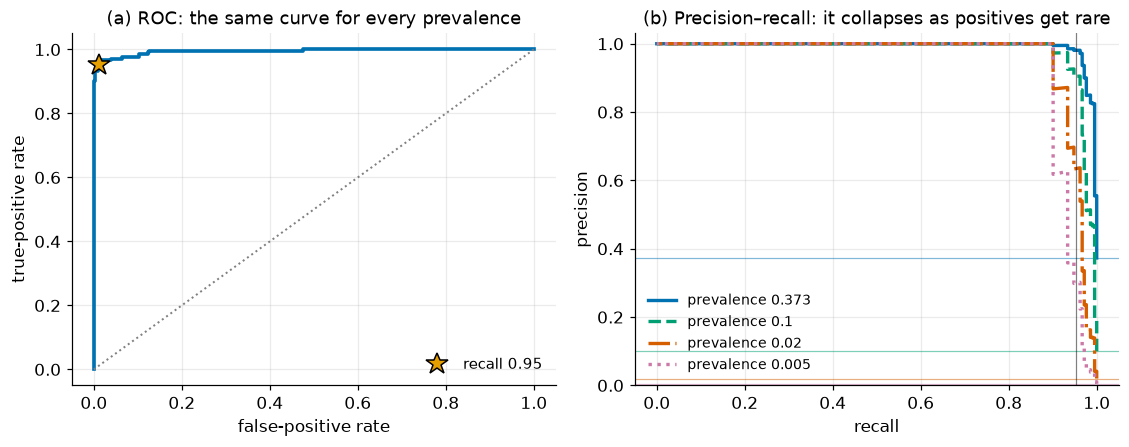

In [27]:
score = oof["logistic regression"]
i95 = int(np.searchsorted(tpr, 0.95))                          # first threshold with recall >= 0.95
t95, tpr95, fpr95 = thr[i95], tpr[i95], fpr[i95]
print(f"operating point: threshold {t95:.4f}, recall {tpr95:.4f}, false-positive rate {fpr95:.4f}\n")

prevalences = [0.373, 0.10, 0.02, 0.005]
n_pos, n_neg = int(y_m.sum()), int((1 - y_m).sum())
rows, pr_curves = [], {}
for pi_ in prevalences:
    w = np.where(y_m == 1, pi_ / (1 - pi_) * n_neg / n_pos, 1.0)               # weights that give the prevalence pi_
    prec_weighted = precision_score(y_m, (score >= t95).astype(int), sample_weight=w)
    prec_formula = pi_ * tpr95 / (pi_ * tpr95 + (1 - pi_) * fpr95)
    pr_curves[pi_] = precision_recall_curve(y_m, score, sample_weight=w)[:2]
    rows.append({"prevalence": pi_, "AUC": roc_auc_score(y_m, score, sample_weight=w),
                 "average precision": average_precision_score(y_m, score, sample_weight=w),
                 "precision at recall 0.95 (weighted)": prec_weighted, "precision at recall 0.95 (formula)": prec_formula})
print(pd.DataFrame(rows).round(4).to_string(index=False))


# Figure 5.10 — ROC curve and PR curves for different prevalences
def figure_5_10():
    fig, axes = plt.subplots(1, 2, figsize=(10.4, 4.2))
    ax = axes[0]
    ax.plot(fpr, tpr, color=BLUE, linewidth=2.4)
    ax.plot([fpr95], [tpr95], marker="*", markersize=15, color=ORANGE, markeredgecolor="black", linestyle="none", label="recall 0.95")
    ax.plot([0, 1], [0, 1], color="gray", linestyle=":", linewidth=1.3)
    ax.set(xlabel="false-positive rate", ylabel="true-positive rate", title="(a) ROC: the same curve for every prevalence")
    ax.legend(frameon=False, fontsize=9.5, loc="lower right")
    ax = axes[1]
    styles = {0.373: (BLUE, "-"), 0.10: (GREEN, "--"), 0.02: (VERMILION, "-."), 0.005: (PURPLE, ":")}
    for pi_, (color, ls) in styles.items():
        prec_c, rec_c = pr_curves[pi_]
        ax.plot(rec_c, prec_c, color=color, linestyle=ls, linewidth=2.2, label=f"prevalence {pi_}")
        ax.axhline(pi_, color=color, linewidth=0.8, alpha=0.5)
    ax.axvline(tpr95, color="black", linewidth=0.8, alpha=0.5)
    ax.set(xlabel="recall", ylabel="precision", title="(b) Precision–recall: it collapses as positives get rare", ylim=(0, 1.03))
    ax.legend(frameon=False, fontsize=9.3, loc="lower left")
    fig.tight_layout()
    plt.show()


figure_5_10()

The ROC curve is the same for every prevalence, and so is the AUC, 0.9947. The precision at the operating point (recall 0.95, false-positive rate 1.1%) is a different matter: it falls from 0.981 at the real prevalence of 37% to 0.904 at 10%, **0.634 at 2%** and **0.299 at 0.5%**, and the weighted computation agrees with the formula to four decimals. At a prevalence of 0.5%, seven alarms out of ten would be false, although the classifier has a false-positive rate of 1% and an AUC of 0.995. The average precision falls too (0.993, 0.980, 0.957, 0.934), and Figure 5.10 shows the PR curves sinking toward the horizontal line of the prevalence.

The practical rule: the **ROC curve and the AUC** describe how well a score *ranks* positives above negatives, independently of the prevalence; when positives are rare (fraud, rare diseases, defects) and false alarms are what hurts, look at the **precision–recall curve** and at the precision at the recall that you need, and always state the **prevalence of the test set** next to any precision.

### 5.6.4 Costs, thresholds and calibration

Which threshold should we use? If a false negative costs $c_{FN}$ and a false positive costs $c_{FP}$, and the classifier outputs a **calibrated** probability $\hat p(\mathbf{x}) = \mathbb{P}(y = 1 \mid \mathbf{x})$, the decision that minimizes the expected cost is obtained by comparing the expected costs of the two decisions:
$$
\underbrace{(1-\hat p)\,c_{FP}}_{\text{cost of predicting positive}} \;\le\; \underbrace{\hat p\,c_{FN}}_{\text{cost of predicting negative}}
\iff \hat p \;\ge\; t^\ast = \frac{c_{FP}}{c_{FP} + c_{FN}}.
$$
For equal costs $t^\ast = \tfrac12$, the familiar rule; if missing a cancer is ten times worse than a false alarm, $t^\ast = 1/11 \approx 0.09$. The rule is the cost-sensitive version of the Bayes classifier of Section 3.2.2, and it shows that **the threshold is a decision about costs, not a property of the model.**

It relies on the probabilities being **calibrated**: among all the patients to whom the model gives a score near 0.3, about 30% should be malignant. The **reliability diagram** checks this: it groups the predictions into bins by score and plots, for each bin, the observed fraction of positives against the mean score. A measure of the quality of the probabilities themselves is the **Brier score**, the mean squared difference between the predicted probability and the 0/1 outcome (lower is better).

In practice we do not trust the theoretical threshold blindly; we **choose the threshold with data**, and, as for every choice, not with the test set. The recipe below uses out-of-fold scores on the training set to find the threshold that minimizes the observed cost, and then looks at the test set once. We take a new split of the 569 patients (70% training, 30% test), $c_{FP} = 1$ and $c_{FN} = 10$.

398 training patients, 171 test patients (64 malignant)


                          rule  threshold  FN on test  FP on test  mean cost on test
        conventional threshold     0.5000           2           1             0.1228
      theory: c_FP/(c_FP+c_FN)     0.0909           0          11             0.0643
minimizes the out-of-fold cost     0.0750           0          13             0.0760
logistic regression: Brier score 0.0208
5-NN: Brier score 0.0278
baseline (always the prevalence 0.373): Brier score 0.2338


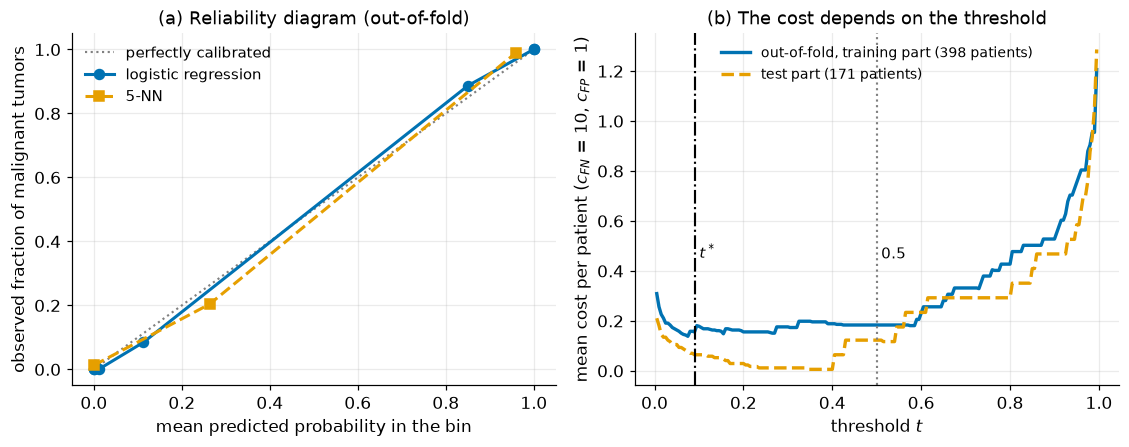

In [28]:
X_t1, X_t2, y_t1, y_t2 = train_test_split(X_bc, y_m, test_size=0.3, random_state=11, stratify=y_m)
c_fp, c_fn = 1.0, 10.0
logit = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
oof_t1 = cross_val_predict(logit, X_t1, y_t1, cv=cv10, method="predict_proba")[:, 1]       # out-of-fold scores on the training part
p_test = logit.fit(X_t1, y_t1).predict_proba(X_t2)[:, 1]                                   # the final model, scored on the test part


def mean_cost(y_true, p, t):
    flagged = p >= t
    return (c_fp * np.sum(flagged & (y_true == 0)) + c_fn * np.sum(~flagged & (y_true == 1))) / len(y_true)


ts = np.linspace(0.005, 0.995, 199)
cost_oof = np.array([mean_cost(y_t1, oof_t1, t) for t in ts])
cost_test = np.array([mean_cost(y_t2, p_test, t) for t in ts])
t_star = c_fp / (c_fp + c_fn)
t_data = float(ts[np.argmin(cost_oof)])
rows = []
for label, t in [("conventional threshold", 0.5), ("theory: c_FP/(c_FP+c_FN)", t_star), ("minimizes the out-of-fold cost", t_data)]:
    tp_, fn_, fp_, tn_ = confusion_counts(y_t2, (p_test >= t).astype(int))
    rows.append({"rule": label, "threshold": t, "FN on test": fn_, "FP on test": fp_, "mean cost on test": mean_cost(y_t2, p_test, t)})
print(f"{len(y_t1)} training patients, {len(y_t2)} test patients ({int(y_t2.sum())} malignant)")
print(pd.DataFrame(rows).round(4).to_string(index=False))

# calibration of the out-of-fold scores of Section 5.6.1 (all 569 patients)
cal = {}
for name in ["logistic regression", "5-NN"]:
    cal[name] = calibration_curve(y_m, oof[name], n_bins=8, strategy="quantile")[::-1]
    print(f"{name}: Brier score {brier_score_loss(y_m, oof[name]):.4f}")
print(f"baseline (always the prevalence {y_m.mean():.3f}): Brier score {brier_score_loss(y_m, np.full(len(y_m), y_m.mean())):.4f}")


# Figure 5.11 — calibration and the cost of the threshold
def figure_5_11():
    fig, axes = plt.subplots(1, 2, figsize=(10.4, 4.2))
    ax = axes[0]
    ax.plot([0, 1], [0, 1], color="gray", linestyle=":", linewidth=1.4, label="perfectly calibrated")
    for name, (color, marker, ls) in {"logistic regression": (BLUE, "o", "-"), "5-NN": (ORANGE, "s", "--")}.items():
        mean_pred, frac_pos = cal[name]
        ax.plot(mean_pred, frac_pos, color=color, marker=marker, linestyle=ls, linewidth=2, markersize=6.5, label=name)
    ax.set(xlabel="mean predicted probability in the bin", ylabel="observed fraction of malignant tumors",
           title="(a) Reliability diagram (out-of-fold)")
    ax.legend(frameon=False, fontsize=9.5, loc="upper left")
    ax = axes[1]
    ax.plot(ts, cost_oof, color=BLUE, linewidth=2.2, label="out-of-fold, training part (398 patients)")
    ax.plot(ts, cost_test, color=ORANGE, linewidth=2.2, linestyle="--", label="test part (171 patients)")
    ax.axvline(0.5, color="gray", linestyle=":", linewidth=1.4)
    ax.axvline(t_star, color="black", linestyle="-.", linewidth=1.4)
    ax.text(0.51, 0.45, "0.5", fontsize=9.5)
    ax.text(t_star + 0.01, 0.45, "$t^*$", fontsize=10)
    ax.set(xlabel="threshold $t$", ylabel="mean cost per patient ($c_{FN}$ = 10, $c_{FP}$ = 1)", title="(b) The cost depends on the threshold")
    ax.legend(frameon=False, fontsize=9.3, loc="upper center")
    fig.tight_layout()
    plt.show()


figure_5_11()

On the test part, with $c_{FN} = 10\,c_{FP}$, the conventional threshold 0.5 leaves 2 false negatives and 1 false positive, a mean cost of 0.123 per patient. The theoretical threshold $t^\ast = 1/11 = 0.091$ catches every malignant tumor at the price of 11 false alarms, and halves the cost (0.064). The threshold selected on the out-of-fold cost of the training part, 0.075, also leaves no false negative, with 13 false alarms (cost 0.076). Panel (b) shows that the cost curve is flat over a wide range of thresholds and rises sharply only beyond 0.6: for a classifier that separates the classes as well as this one, the exact threshold matters less than keeping it away from the extremes. The test curve has its minimum between about 0.2 and 0.4, but that is a piece of information that we are *not* allowed to use: the threshold was set on the training part, and the test part serves only to report.

The reliability diagram (panel (a)) shows that on this data set both models are close to calibrated, and the Brier score confirms that their probabilities are far better than the constant prediction of the prevalence (0.0208 for the logistic regression, 0.0278 for the 5-NN, 0.2338 for the baseline), which is why the theoretical threshold worked well here. This is not guaranteed in general: models with many features or very flexible models (boosted trees, neural networks) are often overconfident, and then $t^\ast$ should be replaced by a threshold chosen on validation data, or the probabilities should be recalibrated on held-out data (`CalibratedClassifierCV` implements Platt scaling and isotonic regression).

### 5.6.5 Beyond two classes, and beyond classification

**Several classes.** The confusion matrix becomes a $C \times C$ table, and precision, recall and $F_1$ are computed **per class** (each class in turn as the positive one, "one against the rest"). To summarize them in one number there are three averages: **macro** (the plain mean over the classes: every class counts the same, so rare classes weigh as much as common ones), **weighted** (the mean weighted by the number of examples of each class) and **micro** (pool the counts of all classes before computing the ratio: for single-label problems the micro-averaged precision, recall and $F_1$ all equal the accuracy). Below, the Digits data with 3-NN and 10-fold out-of-fold predictions.

         precision  recall     F1  support
digit 0      1.000   1.000  1.000      178
digit 1      0.978   1.000  0.989      182
digit 2      1.000   0.994  0.997      177
digit 3      0.973   0.989  0.981      183
digit 4      0.995   1.000  0.997      181
digit 5      0.994   0.978  0.986      182
digit 6      0.995   1.000  0.997      181
digit 7      0.989   0.994  0.992      179
digit 8      0.988   0.977  0.983      174
digit 9      0.977   0.956  0.966      180

accuracy 0.9889;  macro F1 0.9889;  weighted F1 0.9888;  micro F1 0.9889
most frequent confusions (true -> predicted): [(5, 9, 3), (9, 3, 3), (8, 1, 3)]


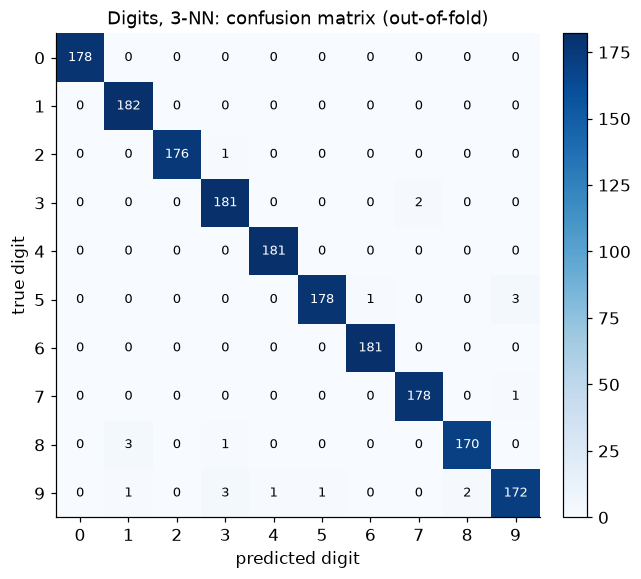

In [29]:
from sklearn.metrics import precision_recall_fscore_support

pred_dg = cross_val_predict(KNeighborsClassifier(n_neighbors=3), X_dg, y_dg, cv=StratifiedKFold(10, shuffle=True, random_state=SEED))
cm_dg = confusion_matrix(y_dg, pred_dg)
prec_c, rec_c, f1_c, support_c = precision_recall_fscore_support(y_dg, pred_dg, zero_division=0)
per_class = pd.DataFrame({"precision": prec_c, "recall": rec_c, "F1": f1_c, "support": support_c}, index=[f"digit {d}" for d in range(10)])
print(per_class.round(3).to_string())
print(f"\naccuracy {accuracy_score(y_dg, pred_dg):.4f};  macro F1 {f1_score(y_dg, pred_dg, average='macro'):.4f};  "
      f"weighted F1 {f1_score(y_dg, pred_dg, average='weighted'):.4f};  micro F1 {f1_score(y_dg, pred_dg, average='micro'):.4f}")
off = cm_dg.copy()
np.fill_diagonal(off, 0)
worst = np.dstack(np.unravel_index(np.argsort(-off, axis=None)[:3], off.shape))[0]
print("most frequent confusions (true -> predicted):", [(int(a), int(b), int(off[a, b])) for a, b in worst])


# Figure 5.12 — the confusion matrix of the Digits
def figure_5_12():
    fig, ax = plt.subplots(figsize=(6.2, 5.4))
    im = ax.imshow(cm_dg, cmap="Blues")
    for i in range(10):
        for j in range(10):
            ax.text(j, i, cm_dg[i, j], ha="center", va="center", fontsize=8.5,
                    color="white" if cm_dg[i, j] > cm_dg.max() / 2 else "black")
    ax.set_xticks(range(10)); ax.set_yticks(range(10))
    ax.grid(False)
    ax.set(xlabel="predicted digit", ylabel="true digit", title="Digits, 3-NN: confusion matrix (out-of-fold)")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    fig.tight_layout()
    plt.show()


figure_5_12()

The accuracy is 0.9889 and the three averages of the $F_1$ score are 0.9889 (macro), 0.9888 (weighted) and 0.9889 (micro, equal to the accuracy). With ten classes of about the same size the averages nearly coincide. They differ when the classes are imbalanced: the macro average then exposes a poor performance on the rare classes that accuracy and the micro average hide. Per class, the hardest digit is 9 (recall 0.956, $F_1$ 0.966), and the most frequent confusions, three images each, are 5 predicted as 9, 9 predicted as 3 and 8 predicted as 1 (Figure 5.12). Reading a confusion matrix tells *where* a model fails, which a single number never does, and it is often the first step toward fixing it.

**Regression.** For a numerical target the errors are differences, and the usual summaries are the **mean squared error** $\text{MSE} = \frac1n\sum_i (y_i - \hat y_i)^2$ (the loss of Chapter 4 and the one that least squares minimizes, but in squared units and sensitive to outliers), its square root **RMSE** (in the units of $y$), the **mean absolute error** $\text{MAE} = \frac1n\sum_i \lvert y_i - \hat y_i\rvert$ (more robust to outliers, less so to large errors that matter), and the **coefficient of determination**
$$
R^2 = 1 - \frac{\sum_i (y_i - \hat y_i)^2}{\sum_i (y_i - \bar y)^2} = 1 - \frac{\text{MSE of the model}}{\text{MSE of the constant prediction } \bar y}.
$$
$R^2$ is the *fraction of the variance of $y$ explained* relative to the baseline that always predicts the mean. It is 1 for a perfect model, 0 for the baseline, and **negative** if the model is worse than the baseline (which can happen on new data). The choice among them is, again, a decision about what errors cost. Here they are for the Diabetes data (the target is a measure of disease progression after one year), computed out-of-fold with 5-fold cross-validation, for the mean baseline, a linear model and 20-NN.

In [30]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.neighbors import KNeighborsRegressor

X_db, y_db = load_diabetes(return_X_y=True)
cv5 = KFold(5, shuffle=True, random_state=SEED)
regressors = {
    "baseline: mean of the training targets": DummyRegressor(strategy="mean"),
    "linear regression": LinearRegression(),
    "20-NN": make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=20)),
}
rows = {}
for name, model in regressors.items():
    p = cross_val_predict(model, X_db, y_db, cv=cv5)
    rows[name] = {"MSE": mean_squared_error(y_db, p), "RMSE": np.sqrt(mean_squared_error(y_db, p)),
                  "MAE": mean_absolute_error(y_db, p), "R2": r2_score(y_db, p)}
print(pd.DataFrame(rows).T.round(3).to_string())
print(f"\nvariance of the target: {y_db.var():.1f}   check: 1 - MSE/variance for linear regression = {1 - rows['linear regression']['MSE'] / y_db.var():.3f}")

                                             MSE    RMSE     MAE     R2
baseline: mean of the training targets  5969.708  77.264  65.985 -0.007
linear regression                       3014.323  54.903  44.260  0.492
20-NN                                   3282.168  57.290  46.810  0.447

variance of the target: 5929.9   check: 1 - MSE/variance for linear regression = 0.492


The baseline that predicts the training mean has an MSE of 5,970, practically the variance of the target (5,930), and an $R^2$ of $-0.007$: slightly negative, because the mean of the training folds is not exactly the mean of the held-out fold. The linear regression reaches an MSE of 3,014 (RMSE 54.9, MAE 44.3), so it explains 49% of the variance; the 20-NN is slightly worse (MSE 3,282, $R^2$ = 0.447), in agreement with the lesson of Chapter 4. The last line verifies the identity $R^2 = 1 - \text{MSE}/\text{variance}$ numerically. The four measures rank the three models in the same way here; with outliers in the target they can disagree, and then the choice among them is a decision about which errors matter.

## 5.7 A complete protocol

We now put the pieces together, on the Breast Cancer split of Section 5.4.1 (426 training patients, 143 test patients that nobody has looked at). The protocol is the same for any problem:

1. **Set the test set aside**, stratified, before looking at anything else, and do not touch it until step 6.
2. **Choose the metric** that reflects the use of the model (here: the AUC to rank the candidates; accuracy, recall and precision to describe the final one).
3. **Compute a baseline**, the score of the trivial predictor, so that every number has a reference.
4. **Tune and compare the candidates by cross-validation on the training set only**, with the preprocessing inside the pipeline. The search is over several *families* of models at once.
5. **Estimate the performance of the whole procedure** with nested cross-validation (optional but informative), and refit the winner on the whole training set.
6. **Evaluate the refitted model once on the test set**; report the metric with a confidence interval, next to the baseline.

In [31]:
from sklearn.linear_model import LogisticRegression

y_tr_m, y_te_m = 1 - y_trbc, 1 - y_tebc                                    # 1 = malignant; the split of Section 5.4.1

# step 3: baseline (the trivial predictor, scored by cross-validation on the training set)
base_cv = cross_val_score(DummyClassifier(strategy="most_frequent"), X_trbc, y_tr_m, cv=cv_rep).mean()
print(f"baseline (always benign): cross-validated accuracy {base_cv:.3f}, AUC 0.5 by construction")

# step 4: search over two families of models, scored by the AUC
final_pipe = Pipeline([("scale", StandardScaler()), ("model", KNeighborsClassifier())])
families = [
    {"model": [KNeighborsClassifier()], "model__n_neighbors": [3, 5, 7, 9, 11, 15, 21, 31], "model__weights": ["uniform", "distance"]},
    {"model": [LogisticRegression(max_iter=5000)], "model__C": [0.001, 0.01, 0.03, 0.1, 0.3, 1, 3, 10, 100]},
]
final_search = GridSearchCV(final_pipe, families, cv=cv_rep, scoring="roc_auc").fit(X_trbc, y_tr_m)
res = pd.DataFrame(final_search.cv_results_)
res["family"] = res["param_model"].map(lambda m: type(m).__name__)
print("\nbest CV AUC per family:")
print(res.groupby("family")["mean_test_score"].max().round(4).to_string())
print(f"winner: {final_search.best_params_['model']!r}, parameters { {k: v for k, v in final_search.best_params_.items() if k != 'model'} }, CV AUC {final_search.best_score_:.4f}")

# step 5: nested cross-validation of the whole procedure (outer 5 folds, inner 5 folds)
inner = GridSearchCV(final_pipe, families, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), scoring="roc_auc")
nested_auc = cross_val_score(inner, X_trbc, y_tr_m, cv=StratifiedKFold(5, shuffle=True, random_state=SEED + 1), scoring="roc_auc")
print(f"\nnested CV AUC of the procedure: {nested_auc.mean():.4f}  (folds: {nested_auc.round(3).tolist()})")

baseline (always benign): cross-validated accuracy 0.627, AUC 0.5 by construction



best CV AUC per family:
family
KNeighborsClassifier    0.9917
LogisticRegression      0.9959
winner: LogisticRegression(max_iter=5000), parameters {'model__C': 0.3}, CV AUC 0.9959



nested CV AUC of the procedure: 0.9916  (folds: [0.986, 0.995, 0.986, 0.995, 0.996])


In [32]:
# step 6: the test set, used once
p_te = final_search.predict_proba(X_tebc)[:, 1]                          # estimated probability of malignancy
pred_te = final_search.predict(X_tebc)
tp_, fn_, fp_, tn_ = confusion_counts(y_te_m, pred_te)
n_err = fn_ + fp_
wilson_ci = stats.binomtest(n_err, len(y_te_m)).proportion_ci(confidence_level=0.95, method="wilson")
base_acc = DummyClassifier(strategy="most_frequent").fit(X_trbc, y_tr_m).score(X_tebc, y_te_m)
print(f"test set of {len(y_te_m)} patients ({int(y_te_m.sum())} malignant)")
print(f"confusion matrix: TP {tp_}, FN {fn_}, FP {fp_}, TN {tn_}")
print(f"accuracy {1 - n_err / len(y_te_m):.4f}  (95% Wilson interval for the error rate: [{wilson_ci.low:.3f}, {wilson_ci.high:.3f}]),"
      f" baseline accuracy {base_acc:.4f}")
print(f"recall {tp_ / (tp_ + fn_):.4f}, precision {tp_ / (tp_ + fp_):.4f}, AUC {roc_auc_score(y_te_m, p_te):.4f}")
print(f"\nAUC: CV of the winner {final_search.best_score_:.4f}, nested CV of the procedure {nested_auc.mean():.4f}, test set {roc_auc_score(y_te_m, p_te):.4f}")

test set of 143 patients (53 malignant)
confusion matrix: TP 52, FN 1, FP 1, TN 89
accuracy 0.9860  (95% Wilson interval for the error rate: [0.004, 0.050]), baseline accuracy 0.6294
recall 0.9811, precision 0.9811, AUC 0.9975

AUC: CV of the winner 0.9959, nested CV of the procedure 0.9916, test set 0.9975


**Reading the output.** The baseline reaches a cross-validated accuracy of 0.627. The search over the two families gives a best CV AUC of 0.9917 for the $k$-NN and 0.9959 for the logistic regression, which wins with $C = 0.3$. The nested cross-validation of the whole procedure gives an AUC of 0.9916, slightly lower than the 0.9959 of `best_score_`: the difference of 0.004 is the optimism of tuning, small here because the problem is easy and the training set is not tiny. On the test set the refitted model makes 2 errors in 143 patients: accuracy 0.986, against 0.629 for the baseline; recall 0.981, precision 0.981, AUC 0.9975. The three AUC values agree within the noise. The 95% Wilson interval for the error rate, **[0.4%, 5.0%]**, is the honest summary of what 143 test patients can say: the model is clearly good, and the test set cannot distinguish an error rate of 1% from one of 4%.

A report of this experiment would read: *"A standardized logistic regression ($C = 0.3$), chosen among $k$-NN and logistic regression by repeated 5-fold cross-validation on 426 patients, achieves on 143 held-out patients an accuracy of 98.6% (95% Wilson interval for the error rate 0.4% to 5.0%), against 62.9% for the majority-class baseline; recall 98.1%, precision 98.1%, AUC 0.9975."* Notice what it contains: the procedure, the sizes, the baseline, the interval, and numbers computed on data that took no part in any choice.

:::{admonition} Pitfall — the temptation of a second look
:class: warning
Suppose the test result had been disappointing, and we went back to change the model and tested again on the same 143 patients. From that moment the test set would have been a validation set, and the final number would be optimistic by the amount of Section 5.2.3. If a second round is unavoidable, the honest options are to collect (or hold out) a **new** test set, or to report both the failure of the first round and the second result as exploratory.
:::

## 5.8 Summary

- **Three roles for data.** Fit on the training set, choose on the validation set (or by cross-validation), report on the test set, **once**. A set that has taken part in a decision is no longer an honest judge: the winner's score on the data that selected it overstates its performance, by an amount that grows with the logarithm of the number of candidates and shrinks with the size of the validation set (Figure 5.2; Theorem 3.1 from the other side).
- **Hold-out estimates are noisy.** The standard error of an accuracy on $m$ examples is $\sqrt{p(1-p)/m}$; on a few dozen examples it is several points, the selected hyperparameter is itself random (Figure 5.1), and resolving a difference of one point takes thousands of examples.
- **Cross-validation** reuses every example for training and validation in turn, at the cost of $K$ fits. Its estimate is pessimistic (it measures the model trained on $n(K-1)/K$ examples, so the bias is read off the learning curve), noisy (several points at $n = 100$), and its naive standard error is too small, because the folds overlap. It estimates the performance of a **procedure**, not of the particular fitted model. Defaults: $K = 5$ or $10$, stratified, repeated when data are scarce.
- **Respect the structure of the data.** Shuffle (or stratify) when the file is ordered, use `GroupKFold` when rows come in groups (random folds gave 95% accuracy on pure noise in the patients' example), use time-ordered splits when predicting the future, and put every data-dependent step inside the pipeline.
- **Tuning.** Grid search is simple but its cost multiplies; random search tries more values of the hyperparameters that matter, on a log scale for strengths and rates. The CV scores of the top configurations are usually tied within the noise: apply the **one-standard-error rule** and prefer the simpler model. `best_score_` is optimistic; **nested cross-validation** (cost $\approx K_{\text{out}}$ times higher) estimates the performance of the whole tuning procedure.
- **Comparing models.** A paired comparison on the same examples is sharper than two separate scores: McNemar's exact test uses only the discordant examples. The naive paired $t$-test over repeated splits is invalid (43.5% false alarms at the 5% level in Section 5.5.2); the corrected resampled $t$-test of Nadeau and Bengio is valid but, with a few hundred examples, cannot detect differences of one or two points. Differences within the noise should not drive decisions.
- **Metrics.** Accuracy hides the balance between the two kinds of error (a baseline that always predicts the majority class reaches 63% on Breast Cancer). **Recall** and **precision** answer different questions; **$F_\beta$** combines them. The **ROC curve** shows the trade-off of a score as the threshold moves and its **AUC** is the probability that a random positive outranks a random negative (Proposition 5.1); it is independent of the prevalence. When positives are rare, the **precision–recall curve** is the more informative one: precision $= \pi\,\text{TPR}/(\pi\,\text{TPR} + (1-\pi)\,\text{FPR})$ collapses with $\pi$.
- **Thresholds are decisions about costs.** For calibrated probabilities the cost-minimizing rule is $\hat p \ge c_{FP}/(c_{FP}+c_{FN})$; check calibration with a reliability diagram and the Brier score, and choose the threshold with validation data, never with the test set.
- **Other targets.** For several classes use the confusion matrix and per-class precision and recall, with macro, weighted or micro averages; for regression, MSE, RMSE, MAE and $R^2 = 1 - \text{MSE}/\text{Var}(y)$, always against the mean-prediction baseline.
- **The protocol.** Set the test set aside; choose the metric; compute a baseline; tune and compare by cross-validation on the training set, inside pipelines; refit; evaluate **once** on the test set and report the number with its interval, the baseline and the sizes.

### Data sources

- *Wine*: M. Forina et al., *PARVUS: An Extendible Package for Data Exploration, Classification and Correlation*, Institute of Pharmaceutical and Food Analysis and Technologies, Genoa (1991). Bundled with scikit-learn.
- *Digits*: E. Alpaydin and C. Kaynak, "Optical Recognition of Handwritten Digits", UCI Machine Learning Repository (1998). The test portion of the data set, 1,797 images of $8\times 8$ pixels, is bundled with scikit-learn.
- *Breast Cancer Wisconsin (Diagnostic)*: W. N. Street, W. H. Wolberg and O. L. Mangasarian, "Nuclear feature extraction for breast tumor diagnosis", *IS&T/SPIE 1993 International Symposium on Electronic Imaging: Science and Technology*, volume 1905, 861–870 (1993). Bundled with scikit-learn.
- *Diabetes*: B. Efron, T. Hastie, I. Johnstone and R. Tibshirani, "Least Angle Regression", *Annals of Statistics* (with discussion), 407–499 (2004). Bundled with scikit-learn.
- *Simulated or constructed data*: the coin-flip labels of Sections 5.4.3 and 5.5.2 (real features, fair coin-flip labels), the simulated patients of Section 5.3.3, the schematic of Section 5.4.2, and the re-weighted prevalences of Section 5.6.3 are **constructions**, used because the comparison needs a situation where the truth is known.

### Further reading

- M. Stone, "Cross-validatory choice and assessment of statistical predictions", *Journal of the Royal Statistical Society B* 36(2), 111–147 (1974), and S. Geisser, "The predictive sample reuse method with applications", *Journal of the American Statistical Association* 70(350), 320–328 (1975). The origins of cross-validation.
- T. Hastie, R. Tibshirani and J. Friedman, *The Elements of Statistical Learning*, 2nd ed., Springer, 2009. Chapter 7 (model assessment and selection), including the one-standard-error rule and the right and wrong ways to cross-validate.
- S. Arlot and A. Celisse, "A survey of cross-validation procedures for model selection", *Statistics Surveys* 4, 40–79 (2010).
- R. Kohavi, "A study of cross-validation and bootstrap for accuracy estimation and model selection", *Proceedings of the 14th International Joint Conference on Artificial Intelligence (IJCAI)*, 1137–1143 (1995). The empirical case for stratified 10-fold cross-validation.
- Y. Bengio and Y. Grandvalet, "No unbiased estimator of the variance of $K$-fold cross-validation", *Journal of Machine Learning Research* 5, 1089–1105 (2004).
- S. Bates, T. Hastie and R. Tibshirani, "Cross-validation: what does it estimate and how well does it do it?", *Journal of the American Statistical Association* 119(546), 1434–1445 (2024). What cross-validation estimates, and why its naive confidence intervals are too narrow.
- G. C. Cawley and N. L. C. Talbot, "On over-fitting in model selection and subsequent selection bias in performance evaluation", *Journal of Machine Learning Research* 11, 2079–2107 (2010), and S. Varma and R. Simon, "Bias in error estimation when using cross-validation for model selection", *BMC Bioinformatics* 7, 91 (2006). The case for nested cross-validation.
- J. Bergstra and Y. Bengio, "Random search for hyper-parameter optimization", *Journal of Machine Learning Research* 13, 281–305 (2012).
- L. Breiman, J. Friedman, R. Olshen and C. Stone, *Classification and Regression Trees*, Wadsworth, 1984. Where the one-standard-error rule comes from.
- T. G. Dietterich, "Approximate statistical tests for comparing supervised classification learning algorithms", *Neural Computation* 10(7), 1895–1923 (1998), and C. Nadeau and Y. Bengio, "Inference for the generalization error", *Machine Learning* 52(3), 239–281 (2003). Comparing algorithms; the corrected resampled $t$-test.
- Q. McNemar, "Note on the sampling error of the difference between correlated proportions or percentages", *Psychometrika* 12(2), 153–157 (1947).
- J. A. Hanley and B. J. McNeil, "The meaning and use of the area under a receiver operating characteristic (ROC) curve", *Radiology* 143(1), 29–36 (1982), and T. Fawcett, "An introduction to ROC analysis", *Pattern Recognition Letters* 27(8), 861–874 (2006).
- J. Davis and M. Goadrich, "The relationship between precision–recall and ROC curves", *Proceedings of the 23rd International Conference on Machine Learning (ICML)*, 233–240 (2006), and T. Saito and M. Rehmsmeier, "The precision–recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets", *PLoS ONE* 10(3), e0118432 (2015).
- C. Elkan, "The foundations of cost-sensitive learning", *Proceedings of the 17th International Joint Conference on Artificial Intelligence (IJCAI)*, 973–978 (2001). The threshold $c_{FP}/(c_{FP}+c_{FN})$.
- A. Niculescu-Mizil and R. Caruana, "Predicting good probabilities with supervised learning", *Proceedings of the 22nd International Conference on Machine Learning (ICML)*, 625–632 (2005), and G. W. Brier, "Verification of forecasts expressed in terms of probability", *Monthly Weather Review* 78(1), 1–3 (1950). Calibration and the Brier score.
- S. Kapoor and A. Narayanan, "Leakage and the reproducibility crisis in machine-learning-based science", *Patterns* 4(9), 100804 (2023), and D. R. Roberts et al., "Cross-validation strategies for data with temporal, spatial, hierarchical, or phylogenetic structure", *Ecography* 40(8), 913–929 (2017). Leakage in practice, and splits for structured data.

## 5.9 Exercises

Difficulty: ★ warm-up, ★★ core, ★★★ challenge. Try each exercise before reading the hint; solutions and detailed outlines are in [Appendix C](../appendices/appendix_c_solutions.ipynb).

### Manual (analytical) exercises

**Exercise 5.1 ★ — How much can a validation set tell?** A model gets 87 of 100 validation examples right. (a) Compute the standard error of the accuracy and the normal-approximation 95% interval $\hat p \pm 1.96\operatorname{SE}$. (b) How many validation examples are needed for a 95% half-width of at most 0.02, if the accuracy is about 0.9? And in the worst case $p = \tfrac12$? (c) Compare with the number given by Hoeffding's inequality (Section 3.10.2) for the same half-width and confidence, and explain the difference. (d) A second model is evaluated on the *same* 100 examples: both models are right on 85 of them, only the first on 5, only the second on 2, and both are wrong on 8. Compute the exact McNemar $p$-value for the null hypothesis that the two models have the same error rate.

*Hint.* For (b) solve $1.96\sqrt{p(1-p)/m} \le 0.02$ for $m$. For (d), only the discordant examples count: $b = 5$, $c = 2$.

**Exercise 5.2 ★ — Counting model fits.** A pipeline is tuned with a grid of 5 values for one hyperparameter and 4 for another, by 5-fold cross-validation repeated 3 times, and the winner is refitted on the whole training set. (a) How many model fits are needed? (b) How many with nested cross-validation, with 5 outer folds and the same inner scheme? (c) How many if the grid is replaced by a random search with 20 draws (same inner scheme)? (d) How many fits does leave-one-out cross-validation need for $n = 1000$ and 12 configurations, refit included? Which of these numbers would make you reconsider the design for a model that takes one minute to fit?

*Hint.* Each configuration costs (number of folds) × (number of repeats) fits; add one for the refit.

**Exercise 5.3 ★★ — ROC and AUC by hand.** A classifier gives the scores $0.9, 0.6, 0.4$ to three positive examples and $0.7, 0.4, 0.2, 0.1$ to four negative examples. (a) List the points of the ROC curve, handling the tie at 0.4 as a block. (b) Compute the AUC with the trapezoid rule, and again as the fraction of (positive, negative) pairs in which the positive has the higher score, counting ties as one half. (c) Find the threshold that maximizes the $F_1$ score and the value of $F_1$ there.

*Hint.* There are $3 \times 4 = 12$ pairs. For (c) evaluate precision and recall at each distinct threshold, predicting positive when the score is at least the threshold.

**Exercise 5.4 ★★ — The cost-optimal threshold.** (a) Derive $t^\ast = c_{FP}/(c_{FP} + c_{FN})$ for a calibrated probability $\hat p$. (b) A fraud detector produces calibrated probabilities. A missed fraud costs 200 and a false alarm costs 5. What is the optimal threshold? (c) The fraud prevalence is 0.5%. At some threshold the detector has TPR 0.90 and FPR 0.02. In 10,000 transactions compute the confusion matrix, the precision, and the expected cost per transaction, and compare with the policies "flag nothing" and "flag everything". (d) How does the optimal threshold change if the costs are doubled for both errors?

*Hint.* For (c), 50 of the 10,000 transactions are fraudulent; the cost is $200\,FN + 5\,FP$.

**Exercise 5.5 ★★★ — Leave-one-out for least squares without refitting.** Let $\mathbf{X}$ be an $n \times d$ matrix of full column rank, $\hat{\boldsymbol\beta} = (\mathbf{X}^\top\mathbf{X})^{-1}\mathbf{X}^\top\mathbf{y}$, $\hat y_i = \mathbf{x}_i^\top\hat{\boldsymbol\beta}$, $e_i = y_i - \hat y_i$, and $h_{ii} = \mathbf{x}_i^\top(\mathbf{X}^\top\mathbf{X})^{-1}\mathbf{x}_i$ (the $i$-th diagonal entry of the hat matrix). (a) Show that the leave-one-out residual, $y_i - \mathbf{x}_i^\top\hat{\boldsymbol\beta}_{(i)}$ with $\hat{\boldsymbol\beta}_{(i)}$ fitted without example $i$, is $e_i/(1 - h_{ii})$. (b) Deduce that the leave-one-out mean squared error (PRESS$/n$) can be computed from a single fit. (c) What does the formula say about examples with $h_{ii}$ close to 1?

*Hint.* Write $\mathbf{X}_{(i)}^\top\mathbf{X}_{(i)} = \mathbf{X}^\top\mathbf{X} - \mathbf{x}_i\mathbf{x}_i^\top$ and use the Sherman–Morrison formula $(\mathbf{A} - \mathbf{u}\mathbf{u}^\top)^{-1} = \mathbf{A}^{-1} + \dfrac{\mathbf{A}^{-1}\mathbf{u}\mathbf{u}^\top\mathbf{A}^{-1}}{1 - \mathbf{u}^\top\mathbf{A}^{-1}\mathbf{u}}$; also $\mathbf{X}_{(i)}^\top\mathbf{y}_{(i)} = \mathbf{X}^\top\mathbf{y} - \mathbf{x}_i y_i$.

### Python (computational) exercises

**Exercise 5.6 ★ — Stratified folds from scratch.** (a) Write `stratified_kfold_splits(y, K, seed)` that shuffles the indices of each class and deals them out to the $K$ folds in turn, and returns a list of (train, held-out) index pairs. (b) Check that in every fold the number of examples of each class differs by at most one from the ideal proportion. (c) Take **all** 357 benign tumors of the Breast Cancer data and a random 20 of the 212 malignant ones (an imbalanced data set), and compare, over 50 seeds, plain shuffled 5-fold splits and your stratified splits: the standard deviation across seeds of the 5-fold accuracy of a standardized 5-NN, and the smallest number of malignant examples found in a held-out fold.

*Hint.* Use `np.array_split` on each class's shuffled indices, and give fold $j$ the $j$-th chunk of every class; compare with `cross_val_score` on your list of splits.

**Exercise 5.7 ★★ — How many folds, for another model?** Repeat the experiment of Section 5.3.2 with a **logistic regression** on the Breast Cancer data (a standardized pipeline). In each of 100 repetitions draw a sample of $n = 100$ patients, compute the CV accuracy for $K = 2, 5, 10, 20$, fit on the whole sample and measure the accuracy on the other 469 patients. Report the bias and the spread of $\mathrm{CV}_K - $ test accuracy, and compare with the 3-NN on Digits of Section 5.3.2. Why is the bias for $K = 2$ so much smaller here?

*Hint.* Use `cross_val_score` with `KFold(K, shuffle=True, random_state=...)`. Compute the learning curve of the logistic regression at $n = 50$ and $n = 100$ to explain the result.

**Exercise 5.8 ★★ — Random search with a budget.** Using the training set of Section 5.4.1, compute (once) the 5-fold CV accuracy of each of the 60 configurations of the $k$-NN grid, and the test accuracy of each configuration fitted on the whole training set. For budgets $B = 2, 4, 8, 15, 30, 60$ simulate a random search that evaluates $B$ configurations drawn without replacement (500 repetitions), selects the one with the best CV accuracy, and record the CV accuracy and the **test accuracy** of the selected configuration. Plot both against $B$. At which budget does the search stop paying? What is the difference between the two curves at $B = 60$ (the optimism of the grid search)?

*Hint.* The 60 CV scores can come from `GridSearchCV(...).cv_results_["mean_test_score"]`; for the test scores fit `clone(pipe_bc).set_params(**params)` for each parameter dictionary in `cv_results_["params"]`. Remember that the test set of that section was supposed to be kept untouched; for this exercise use a fresh split (for instance `random_state=0`).

**Exercise 5.9 ★★★ — The optimism of tuning as a function of $n$ and of the number of candidates.** With **coin-flip labels** (real features of the Breast Cancer data, fair random labels, true accuracy 0.5 for every model) let each candidate be a 5-NN on 5 randomly chosen standardized features. (a) For $n = 60$ and $m = 1, 4, 16, 64$ candidates, estimate over 40 repetitions the mean of the **best 5-fold CV accuracy** among the $m$ candidates, minus 0.5. (b) For $m = 16$ and $n = 30, 60, 120, 240$, do the same. (c) Compare the results with the bound $\sqrt{\ln m/(2n)}$ of Section 3.6, and say whether the dependence on $m$ and $n$ has the predicted shape.

*Hint.* Draw the labels of the sample once per repetition, and the $m$ feature subsets once per repetition, so that the candidates compete on the same data. Use a pipeline so that the scaler is fitted inside the folds.

**Exercise 5.10 ★★★ — A cost-sensitive study, repeated.** On the Breast Cancer data (positive class: malignant) and for cost ratios $c_{FN}/c_{FP} = 1, 5, 10, 50$ (with $c_{FP} = 1$), over 50 random 70/30 stratified splits: (a) choose a threshold for a standardized logistic regression from the out-of-fold scores on the training part (10-fold) by minimizing the observed cost; (b) report the mean cost per patient on the test part of three rules, **threshold 0.5**, **theory** $t^\ast$ and **out-of-fold optimum**, with the standard deviation across splits; (c) discuss which rule is best as the ratio grows, and how variable the out-of-fold threshold is.

*Hint.* Reuse `mean_cost` of Section 5.6.4 with `c_fn` as an argument, and a grid of thresholds such as `np.linspace(0.005, 0.995, 199)`. For high ratios the out-of-fold optimum can be very small: compare it with $t^\ast$.

## What comes next

We now have the rules of the game: how to estimate a model's performance, how to choose among models and settings without fooling ourselves, and which numbers to look at. From here on, every method of the book is introduced together with its hyperparameters and evaluated with the protocol of Section 5.7. **Chapter 6** introduces the opposite assumption to $k$-NN, a *global* parametric model: linear regression and linear classification, with their regularized versions (ridge, regularized logistic regression). The inverse regularization strength $C$ that we tuned on a log scale in Section 5.4.2 becomes a quantity that we can analyze, with the bias–variance tools of Chapter 4, and the cross-entropy loss of logistic regression is the Bernoulli negative log-likelihood of Section 2.6.7. **Chapter 7** shows how to find the parameters when there is no closed form (gradient descent), **Chapters 8 and 9** build support vector machines and kernels on the margin bound of Section 3.8, **Chapter 10** returns to irrelevant features with sparse models and feature selection (inside the cross-validation loop, as Section 5.3.3 requires), and **Chapter 11** introduces trees and ensembles, whose probabilities are the typical case of a model that needs the recalibration of Section 5.6.4.